# Predicción del puntaje global de la prueba Saber 11: modelos de regresión, clasificación, segmentación e interpretabilidad

### Andrés Giovanny Rubiano Muñoz "Andy Rubiano"

**Maestría en Inteligencia Artificial**
**Universidad de La Salle**

**Ciencia de Datos**

---

**Fase 3 del proyecto:** modelos más potentes que los de referencia, agrupamiento de los estudiantes según su perfil e interpretación de lo que pesa en las predicciones.

**Caso de estudio:** *Resultados únicos Saber 11*, ICFES, periodo **2022-4**, muestra representativa de **1.000 estudiantes** ([`andyrubiano/saber-11-muestra-2022-4`](https://www.kaggle.com/datasets/andyrubiano/saber-11-muestra-2022-4), CC BY-SA 4.0).

**Punto de partida:** en el cuaderno 02, una regresión lineal se equivocó en promedio por **35 puntos**, con un R² de 0,305, y una regresión logística alcanzó un **F1 macro de 0,48**, y esas son las cifras que hay que superar.

Este cuaderno responde tres preguntas, si es posible predecir mejor el puntaje global con modelos lineales, de árboles y una red neuronal, si es posible predecir mejor el nivel de desempeño con tres algoritmos de clasificación distintos y si existen grupos naturales de estudiantes, que se buscan con K-means y con un método jerárquico. Al final se analiza qué variables pesan más en las predicciones y se guarda todo lo que utiliza el tablero.

## 1. Las reglas de la comparación

Antes de entrenar cualquier modelo conviene fijar las reglas, para que la comparación sea justa. Todos los modelos trabajan con los mismos 700, 150 y 150 estudiantes del cuaderno 02, y si esos archivos no están disponibles, como ocurre en una sesión nueva de Colab, el cuaderno los reconstruye con el mismo código y la misma semilla, de modo que salen idénticos.

Cada modelo tiene unos parámetros de ajuste, llamados **hiperparámetros**, como la profundidad de un árbol o la fuerza de la regularización, y para escogerlos se usa **validación cruzada** sobre el grupo de entrenamiento, que se parte en cinco trozos, se entrena con cuatro y se mide con el que queda por fuera, rotando hasta usarlos todos y repitiendo el proceso tres veces, lo que da quince mediciones por cada combinación. Hacerlo así es necesario porque con solo 150 estudiantes de validación una sola medición dependería demasiado de la suerte.

El mejor modelo de cada bloque se escoge por su resultado en la validación cruzada y el grupo de prueba se usa una sola vez, para que su cifra siga siendo una medición honesta. Como 150 estudiantes son pocos, cada resultado de prueba se acompaña de un **intervalo de confianza**, que indica el rango en el que probablemente estaría el error si el experimento se repitiera con otros estudiantes. Además, en todos los casos se compara el error de entrenamiento con el de prueba para detectar el **sobreajuste**, que ocurre cuando un modelo memoriza los datos de entrenamiento y luego falla con estudiantes nuevos, y la interpretación se hace con dos métodos distintos, la permutación y SHAP, para no depender de uno solo.

Los modelos se escogieron porque cada familia mira los datos de una manera distinta. Los **lineales regularizados**, Ridge, Lasso y ElasticNet, suman los efectos de las variables con pesos controlados y son sencillos y estables, los **ensambles de árboles**, Random Forest y Gradient Boosting, combinan muchos árboles de decisión y captan curvas e interacciones sin necesidad de construirlas a mano, los **modelos de distancia o de margen**, SVM y KNN, clasifican a cada estudiante según a quiénes se parece, y la **red neuronal**, un perceptrón multicapa en PyTorch, puede aproximar casi cualquier relación, aunque necesita muchos datos y cuidado para no memorizar. Por último, los métodos de **agrupamiento**, K-means y jerárquico, no predicen nada, sino que buscan grupos de estudiantes parecidos entre sí.

## 2. Preparación del entorno

Además de las librerías del cuaderno 02, aquí se usan los modelos de árboles, de SVM, de KNN y de agrupamiento de `scikit-learn`, la librería `scipy` para el dendrograma, `shap` para explicar las predicciones y `torch` (PyTorch) para la red neuronal. En Colab todas vienen instaladas y en un computador propio se instalan desde `requirements.txt`. La semilla también se fija en PyTorch para que la red dé el mismo resultado en cada ejecución, y el entrenamiento se hace en el procesador (CPU), que es más que suficiente para 700 estudiantes.

In [1]:
import os, sys, time, warnings, json, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
import seaborn as sns
import sklearn
import joblib
import kagglehub
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, RepeatedKFold, RepeatedStratifiedKFold,
                                     cross_val_score, GridSearchCV, RandomizedSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (mean_absolute_error, root_mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
                             silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score)

try:
    import shap
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"], check=True); import shap
import torch
import torch.nn as nn

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 170); pd.set_option("display.float_format", "{:,.3f}".format)
print("pandas:", pd.__version__, "| numpy:", np.__version__, "| scikit-learn:", sklearn.__version__, "| shap:", shap.__version__, "| torch:", torch.__version__)

IN_COLAB = "google.colab" in sys.modules
def find_project_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate / "README.md").exists() and (candidate / "notebooks").is_dir():
            return candidate
    return start
PROJECT_ROOT = Path("/content/saber11-project") if IN_COLAB else find_project_root()
PROCESSED_DIR, MODELS_DIR, FIG_DIR = PROJECT_ROOT / "data" / "processed", PROJECT_ROOT / "models", PROJECT_ROOT / "assets" / "images" / "data"
for folder in (PROCESSED_DIR, MODELS_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)
N_JOBS = max(1, min(4, os.cpu_count() or 1))
print(f"Entorno: {'Google Colab' if IN_COLAB else 'local'} · {os.cpu_count()} núcleos · raíz: {PROJECT_ROOT}")

pandas: 3.0.6 | numpy: 2.5.4 | scikit-learn: 1.9.1 | shap: 0.54.1 | torch: 2.14.1+cpu
Entorno: local · 16 núcleos · raíz: D:\Universidad de La Salle\2do semestre\Ciencia de datos\Proyecto final\saber11-project


In [2]:
C_BASE, C_ACCENT, C_NEU, C_VERDE, C_MORADO = "#2a78d6", "#eb6834", "#5B7C99", "#2CA02C", "#9467BD"
TINTA, GRIS = "#0b0b0b", "#52514e"
PALETTE = [C_BASE, C_ACCENT, C_VERDE, C_MORADO, "#8C564B", "#E377C2", "#7F7F7F", "#BCBD22"]
sns.set_style("whitegrid"); sns.set_palette(PALETTE)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#d9d8d3", "axes.labelcolor": GRIS, "axes.spines.top": False, "axes.spines.right": False,
    "text.color": TINTA, "xtick.color": GRIS, "ytick.color": GRIS, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12, "grid.color": "#eeede9", "grid.linewidth": 0.8})
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE); torch.manual_seed(RANDOM_STATE)
CLASES = ["Bajo", "Medio", "Alto"]

def save_fig(fig, name):
    path = FIG_DIR / f"{name}.png"; fig.savefig(path, bbox_inches="tight")
    print(f"Figura guardada: {path.relative_to(PROJECT_ROOT) if path.is_relative_to(PROJECT_ROOT) else path}")

def evaluar_regresion(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred), "RMSE": root_mean_squared_error(y_true, y_pred), "R2": r2_score(y_true, y_pred)}

def evaluar_clasificacion(y_true, y_pred, proba=None):
    out = {"exactitud": accuracy_score(y_true, y_pred), "precisión macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
           "exhaustividad macro": recall_score(y_true, y_pred, average="macro", zero_division=0), "F1 macro": f1_score(y_true, y_pred, average="macro", zero_division=0)}
    if proba is not None:
        out["AUC-ROC (ovr)"] = roc_auc_score(y_true, proba, multi_class="ovr", average="macro", labels=sorted(CLASES))
    return out

def ic_bootstrap(y_true, y_pred, funcion, n=1000, seed=RANDOM_STATE):
    """Intervalo de confianza del 95 % por bootstrap de una métrica sobre el conjunto de prueba."""
    rng = np.random.default_rng(seed); y_true, y_pred = np.asarray(y_true), np.asarray(y_pred); vals = []
    for _ in range(n):
        idx = rng.integers(0, len(y_true), len(y_true)); vals.append(funcion(y_true[idx], y_pred[idx]))
    return np.percentile(vals, [2.5, 97.5])

## 3. Datos y división de la fase 2

Se cargan el conjunto limpio, la división en tres grupos, la lista de columnas y los preprocesadores del cuaderno 02, y si falta alguno, la función `preparar_fase2` reconstruye todo desde Kaggle con el mismo código y la misma semilla, de modo que este cuaderno puede ejecutarse por sí solo. Luego se preparan las dos versiones de los datos, la **lineal**, con las categorías convertidas en columnas de ceros y unos y las variables numéricas estandarizadas, que usan Ridge, Lasso, ElasticNet, la SVM, el KNN y la red neuronal, y la **de árboles**, con las categorías convertidas en números y sin estandarizar, que usan el bosque aleatorio y el *boosting*.

In [3]:
ARTEFACTOS = ["saber11_fase2.parquet", "particion.parquet", "columnas.json"]
MODELOS_F2 = ["prep_lineal.joblib", "prep_arboles.joblib", "baseline_ridge.joblib", "baseline_logistica.joblib"]

def preparar_fase2():
    """Reconstruye el conjunto, la partición, los preprocesadores y las referencias de la fase 2 (mismo código y semilla)."""
    SCORE = ["punt_matematicas", "punt_lectura_critica", "punt_sociales_ciudadanas", "punt_c_naturales", "punt_ingles", "punt_global"]
    d = pd.read_csv(kagglehub.dataset_download("andyrubiano/saber-11-muestra-2022-4", path="saber11_muestra_1000.csv"), dtype=str)
    for c in SCORE: d[c] = pd.to_numeric(d[c], errors="coerce").astype("float32")
    d = d.drop_duplicates().set_index("estu_consecutivo")
    AREA = SCORE[:-1]; areas = d[AREA].copy()
    d = d.drop(columns=AREA + ["desemp_ingles", "periodo", "estu_estudiante", "estu_estadoinvestigacion", "estu_privado_libertad", "cole_calendario",
        "cole_bilingue", "cole_cod_dane_establecimiento", "cole_cod_dane_sede", "cole_codigo_icfes", "cole_nombre_establecimiento", "cole_nombre_sede",
        "cole_cod_depto_ubicacion", "cole_cod_mcpio_ubicacion", "cole_mcpio_ubicacion", "estu_cod_depto_presentacion", "estu_cod_mcpio_presentacion",
        "estu_depto_presentacion", "estu_mcpio_presentacion", "estu_cod_reside_depto", "estu_cod_reside_mcpio", "estu_depto_reside", "estu_mcpio_reside",
        "estu_nacionalidad", "estu_pais_reside", "estu_tipodocumento"])
    fami = [c for c in d.columns if c.startswith("fami_")]
    d["cuestionario_incompleto"] = d[fami].isna().any(axis=1).astype("int8")
    for c in fami: d[c] = d[c].fillna("No respondió")
    d["cole_caracter"] = d["cole_caracter"].fillna("No reportado")
    nac = pd.to_datetime(d["estu_fechanacimiento"], format="%d/%m/%Y", errors="coerce")
    d["edad"] = ((pd.Timestamp("2022-09-04") - nac).dt.days / 365.25).round(1); p99 = float(d["edad"].quantile(0.99))
    d["edad_original"] = d["edad"]; d["edad"] = d["edad"].clip(upper=p99); d["extraedad"] = (d["edad_original"] >= 19).astype("int8")
    d = d.drop(columns=["estu_fechanacimiento"])
    edu = {"Ninguno": 0, "Primaria incompleta": 1, "Primaria completa": 2, "Secundaria (Bachillerato) incompleta": 3, "Secundaria (Bachillerato) completa": 4,
           "Técnica o tecnológica incompleta": 5, "Técnica o tecnológica completa": 6, "Educación profesional incompleta": 7, "Educación profesional completa": 8, "Postgrado": 9}
    for p, col in [("madre", "fami_educacionmadre"), ("padre", "fami_educacionpadre")]:
        o = d[col].map(edu); d[f"educ_{p}_ord"] = o.astype("float32"); d[f"educ_{p}_desconocida"] = o.isna().astype("int8")
    d["personas_por_cuarto"] = (d["fami_personashogar"].map({"1 a 2": 1.5, "3 a 4": 3.5, "5 a 6": 5.5, "7 a 8": 7.5, "9 o más": 9.5})
                                / d["fami_cuartoshogar"].map({"Uno": 1, "Dos": 2, "Tres": 3, "Cuatro": 4, "Cinco": 5, "Seis o mas": 6})).astype("float32")
    d["genero_F"] = (d["estu_genero"] == "F").astype("int8"); d = d.drop(columns=["estu_genero", "fami_educacionmadre", "fami_educacionpadre"])
    d["fami_estratovivienda"] = d["fami_estratovivienda"].replace({"Estrato 4": "Estrato 4 a 6", "Estrato 5": "Estrato 4 a 6", "Estrato 6": "Estrato 4 a 6"})
    d["naturaleza_area"] = d["cole_naturaleza"] + " · " + d["cole_area_ubicacion"]
    REG = {"BOGOTÁ": "Bogotá", **{x: "Andina" for x in ["ANTIOQUIA", "BOYACA", "CALDAS", "CUNDINAMARCA", "HUILA", "NORTE SANTANDER", "QUINDIO", "RISARALDA", "SANTANDER", "TOLIMA"]},
           **{x: "Caribe" for x in ["ATLANTICO", "BOLIVAR", "CESAR", "CORDOBA", "LA GUAJIRA", "MAGDALENA", "SUCRE", "SAN ANDRES"]},
           **{x: "Pacífica" for x in ["CAUCA", "CHOCO", "NARIÑO", "VALLE"]}, **{x: "Orinoquía" for x in ["ARAUCA", "CASANARE", "META", "VICHADA"]},
           **{x: "Amazonía" for x in ["AMAZONAS", "CAQUETA", "GUAINIA", "GUAVIARE", "PUTUMAYO", "VAUPES"]}}
    d["region"] = d["cole_depto_ubicacion"].map(REG); d = d.drop(columns=["cole_depto_ubicacion"])
    cortes = d["punt_global"].quantile([1 / 3, 2 / 3]).to_numpy()
    d["nivel_desempeno"] = pd.cut(d["punt_global"], bins=[-np.inf, cortes[0], cortes[1], np.inf], labels=CLASES).astype(str)
    cols = {"NUM_COLS": ["edad", "educ_madre_ord", "educ_padre_ord", "personas_por_cuarto"],
            "BIN_COLS": ["extraedad", "cuestionario_incompleto", "educ_madre_desconocida", "educ_padre_desconocida", "genero_F"],
            "NOM_COLS": ["fami_estratovivienda", "fami_personashogar", "fami_cuartoshogar", "fami_tieneinternet", "fami_tienecomputador", "fami_tieneautomovil",
                         "fami_tienelavadora", "cole_naturaleza", "cole_area_ubicacion", "naturaleza_area", "cole_jornada", "cole_caracter", "cole_genero",
                         "cole_sede_principal", "region"], "AREA_COLS": AREA, "TARGET": "punt_global", "CLASES": CLASES,
            "CORTES_NIVEL": {"bajo_hasta": float(cortes[0]), "medio_hasta": float(cortes[1])}, "P99_EDAD": p99}
    feats = cols["NUM_COLS"] + cols["BIN_COLS"] + cols["NOM_COLS"]
    pos = np.arange(len(d)); est = d["nivel_desempeno"].to_numpy()
    p_tr, p_tmp = train_test_split(pos, test_size=0.30, random_state=RANDOM_STATE, stratify=est)
    p_va, p_te = train_test_split(p_tmp, test_size=0.50, random_state=RANDOM_STATE, stratify=est[p_tmp])
    part = pd.Series("train", index=d.index, name="particion"); part.iloc[p_va] = "val"; part.iloc[p_te] = "test"
    Xtr, ytr, ctr = d.loc[part == "train", feats], d.loc[part == "train", "punt_global"], d.loc[part == "train", "nivel_desempeno"]
    pl = ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), cols["NUM_COLS"]), ("bin", "passthrough", cols["BIN_COLS"]),
                            ("nom", OneHotEncoder(handle_unknown="infrequent_if_exist", sparse_output=False, min_frequency=5, dtype=np.float32), cols["NOM_COLS"])],
                           verbose_feature_names_out=False).set_output(transform="pandas").fit(Xtr)
    pa = ColumnTransformer([("num", SimpleImputer(strategy="median"), cols["NUM_COLS"]), ("bin", "passthrough", cols["BIN_COLS"]),
                            ("nom", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, dtype=np.float32), cols["NOM_COLS"])],
                           verbose_feature_names_out=False).set_output(transform="pandas").fit(Xtr)
    cv = KFold(5, shuffle=True, random_state=RANDOM_STATE)
    alphas = np.logspace(-1, 3, 17); alpha = float(min(alphas, key=lambda a: -cross_val_score(Ridge(alpha=a), pl.transform(Xtr), ytr, cv=cv, scoring="neg_mean_absolute_error").mean()))
    cvs = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
    Cs = np.logspace(-4, 1, 11); C = float(max(Cs, key=lambda c: cross_val_score(LogisticRegression(C=c, max_iter=2000), pl.transform(Xtr), ctr, cv=cvs, scoring="f1_macro").mean()))
    cols.update({"ALPHA_RIDGE": alpha, "C_LOGISTICA": C})
    d.join(areas).to_parquet(PROCESSED_DIR / "saber11_fase2.parquet"); part.to_frame().to_parquet(PROCESSED_DIR / "particion.parquet")
    json.dump(cols, open(PROCESSED_DIR / "columnas.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
    joblib.dump(pl, MODELS_DIR / "prep_lineal.joblib"); joblib.dump(pa, MODELS_DIR / "prep_arboles.joblib")
    joblib.dump(Ridge(alpha=alpha).fit(pl.transform(Xtr), ytr), MODELS_DIR / "baseline_ridge.joblib")
    joblib.dump(LogisticRegression(C=C, max_iter=2000).fit(pl.transform(Xtr), ctr), MODELS_DIR / "baseline_logistica.joblib")

faltan = [a for a in ARTEFACTOS if not (PROCESSED_DIR / a).exists()] + [m for m in MODELOS_F2 if not (MODELS_DIR / m).exists()]
if faltan:
    print(f"Artefactos de la fase 2 no encontrados ({faltan}); se reconstruyen con el mismo código y semilla ..."); t0 = time.time(); preparar_fase2(); print(f"Listo en {time.time() - t0:.0f} s")
else:
    print("Artefactos de la fase 2 encontrados; se reutilizan.")

df = pd.read_parquet(PROCESSED_DIR / "saber11_fase2.parquet")
particion = pd.read_parquet(PROCESSED_DIR / "particion.parquet")["particion"]
COLS = json.load(open(PROCESSED_DIR / "columnas.json", encoding="utf-8"))
NUM_COLS, BIN_COLS, NOM_COLS, AREA_COLS, TARGET = (COLS[k] for k in ["NUM_COLS", "BIN_COLS", "NOM_COLS", "AREA_COLS", "TARGET"])
FEATURES = NUM_COLS + BIN_COLS + NOM_COLS
prep_lineal, prep_arboles = joblib.load(MODELS_DIR / "prep_lineal.joblib"), joblib.load(MODELS_DIR / "prep_arboles.joblib")
ridge_ref, logistica_ref = joblib.load(MODELS_DIR / "baseline_ridge.joblib"), joblib.load(MODELS_DIR / "baseline_logistica.joblib")

partes = {p: (df.loc[particion == p, FEATURES], df.loc[particion == p, TARGET], df.loc[particion == p, "nivel_desempeno"]) for p in ["train", "val", "test"]}
X_train, y_train, c_train = partes["train"]; X_val, y_val, c_val = partes["val"]; X_test, y_test, c_test = partes["test"]
Xl = {p: prep_lineal.transform(X) for p, (X, _, _) in partes.items()}; Xa = {p: prep_arboles.transform(X) for p, (X, _, _) in partes.items()}
assert [len(y) for _, y, _ in partes.values()] == [700, 150, 150]
print(f"Entrenamiento {len(y_train)} · validación {len(y_val)} · prueba {len(y_test)} · lineal {Xl['train'].shape[1]} columnas · árboles {Xa['train'].shape[1]} columnas")

Artefactos de la fase 2 encontrados; se reutilizan.
Entrenamiento 700 · validación 150 · prueba 150 · lineal 70 columnas · árboles 24 columnas


Los archivos del cuaderno 02 están disponibles y se reutilizan, y el código confirma que la división sigue siendo de **700, 150 y 150** estudiantes. La versión lineal de los datos tiene 70 columnas y la de árboles 24, las mismas del cuaderno 02, de modo que todos los modelos se comparan con la referencia exactamente sobre los mismos datos. En una sesión nueva de Colab esta celda reconstruye los archivos desde Kaggle en menos de un minuto.

## 4. ¿Se puede predecir mejor el puntaje global?

### 4.1 La familia lineal: Ridge, Lasso y ElasticNet

Ridge, Lasso y ElasticNet son tres maneras de frenar los pesos de un modelo lineal, y compararlos responde una pregunta práctica, si con 70 columnas muy parecidas entre sí y solo 700 estudiantes conviene quedarse con menos variables o basta con moderar el peso de todas. Ridge, que es el modelo de referencia, reduce todos los pesos pero no elimina ninguno, Lasso puede llevar algunos pesos exactamente a cero, lo que equivale a seleccionar variables y descartar el resto, y ElasticNet combina los dos tipos de freno. En los tres casos la fuerza del freno se elige con validación cruzada.

In [4]:
cv_reg = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
def ajustar(modelo, rejilla, X, y, cv, scoring, n_iter=None):
    buscador = (GridSearchCV(modelo, rejilla, cv=cv, scoring=scoring, n_jobs=N_JOBS) if n_iter is None
                else RandomizedSearchCV(modelo, rejilla, n_iter=n_iter, cv=cv, scoring=scoring, n_jobs=N_JOBS, random_state=RANDOM_STATE))
    t0 = time.time(); buscador.fit(X, y); return buscador, time.time() - t0

def filas_regresion(nombre, modelo, rep, tiempo=np.nan, cv_score=np.nan):
    out = {}
    for p in ["train", "val", "test"]:
        out[(nombre, p)] = evaluar_regresion(partes[p][1], modelo.predict(rep[p]))
    out[(nombre, "train")]["segundos búsqueda"] = tiempo; out[(nombre, "train")]["MAE cv"] = cv_score
    return out

reg = {}
reg.update(filas_regresion("Ridge (referencia)", ridge_ref, Xl, cv_score=-cross_val_score(ridge_ref, Xl["train"], y_train, cv=cv_reg, scoring="neg_mean_absolute_error").mean()))
b_lasso, t = ajustar(Lasso(max_iter=20000), {"alpha": np.logspace(-2, 1.5, 15)}, Xl["train"], y_train, cv_reg, "neg_mean_absolute_error")
lasso = b_lasso.best_estimator_; reg.update(filas_regresion("Lasso", lasso, Xl, t, -b_lasso.best_score_))
b_enet, t = ajustar(ElasticNet(max_iter=20000), {"alpha": np.logspace(-2, 1.5, 10), "l1_ratio": [0.2, 0.5, 0.8]}, Xl["train"], y_train, cv_reg, "neg_mean_absolute_error")
enet = b_enet.best_estimator_; reg.update(filas_regresion("ElasticNet", enet, Xl, t, -b_enet.best_score_))
print(f"Lasso: alpha = {b_lasso.best_params_['alpha']:.3g} · coeficientes distintos de cero: {(lasso.coef_ != 0).sum()} de {len(lasso.coef_)}")
print(f"ElasticNet: {b_enet.best_params_} · coeficientes distintos de cero: {(enet.coef_ != 0).sum()}")
tabla_lineal = pd.DataFrame(reg).T; tabla_lineal.index.names = ["modelo", "parte"]; display(tabla_lineal.round(3))
coef_lasso = pd.Series(lasso.coef_, index=Xl["train"].columns); coef_lasso = coef_lasso[coef_lasso != 0].sort_values(key=np.abs, ascending=False)
print("Variables que Lasso conserva, por magnitud del coeficiente (puntos):"); display(coef_lasso.round(1).head(15).to_frame("coeficiente").T)

Lasso: alpha = 0.178 · coeficientes distintos de cero: 45 de 70
ElasticNet: {'alpha': np.float64(0.05994842503189409), 'l1_ratio': 0.2} · coeficientes distintos de cero: 69


MAE   RMSE    R2  segundos búsqueda  MAE cv
modelo             parte                                               
Ridge (referencia) train 33.267 40.411 0.361                NaN  34.765
                   val   36.593 44.400 0.192                NaN     NaN
                   test  35.003 42.723 0.305                NaN     NaN
Lasso              train 32.718 39.825 0.379              3.908  34.934
                   val   36.942 44.807 0.177                NaN     NaN
                   test  35.221 43.272 0.287                NaN     NaN
ElasticNet         train 33.029 40.135 0.369              0.545  34.763
                   val   36.728 44.517 0.187                NaN     NaN
                   test  34.969 42.749 0.304                NaN     NaN

Variables que Lasso conserva, por magnitud del coeficiente (puntos):


,cole_jornada_SABATINA,cole_genero_FEMENINO,cole_caracter_No reportado,naturaleza_area_NO OFICIAL · RURAL,cole_naturaleza_NO OFICIAL,region_Andina,cole_jornada_NOCHE,fami_personashogar_1 a 2,naturaleza_area_OFICIAL · RURAL,cole_jornada_COMPLETA,extraedad,fami_tieneinternet_Si,region_Orinoquía,fami_cuartoshogar_Tres,fami_estratovivienda_Estrato 1
coeficiente,-21.200,19.100,17.900,13.700,13.500,13.400,-13.400,13.000,-11.200,9.200,-8.300,8.000,7.300,7.200,7.000


Los tres modelos lineales quedan prácticamente empatados, con errores en validación cruzada de 34,77 puntos para Ridge, 34,93 para Lasso y 34,76 para ElasticNet, y de 35,0, 35,2 y 35,0 en el grupo de prueba. Lasso se queda con **45 de las 70 columnas** y descarta las otras 25, pero no gana nada con ello, porque las que elimina corresponden a categorías poco frecuentes a las que Ridge ya les asignaba un peso casi nulo, y ElasticNet termina comportándose casi igual que Ridge, así que con estos datos quitar variables no ayuda.

Los pesos que conserva Lasso cuentan la misma historia que mostró la exploración, estudiar en jornada sabatina resta 21 puntos y en jornada nocturna 13, los colegios femeninos suman 19, los privados 13,5 y en especial los privados rurales 14, la región Andina suma 13, los hogares de una a dos personas 13 y la extraedad resta 8. Si se quiere mejorar, entonces, hay que salir de los modelos lineales.

### 4.2 Ensambles de árboles: Random Forest y Gradient Boosting

Un árbol de decisión hace preguntas sencillas, como si el estudiante tiene más de 18 años o si el colegio es oficial, y le asigna un puntaje a cada camino posible. Un árbol solo se equivoca bastante, pero muchos árboles juntos funcionan mucho mejor, y hay dos formas de combinarlos, el **Random Forest**, que entrena cientos de árboles, cada uno con una muestra distinta de estudiantes y de variables, y luego promedia sus respuestas, y el **Gradient Boosting**, que entrena los árboles en cadena, de manera que cada nuevo árbol se concentra en corregir los errores de los anteriores.

Con 700 estudiantes el riesgo es que los árboles terminen memorizando, por eso la búsqueda de hiperparámetros se concentra en los que controlan la complejidad, como el número mínimo de estudiantes en cada hoja, la profundidad máxima de cada árbol y, en el caso del *boosting*, la velocidad con la que aprende y la cantidad de árboles que usa.

In [5]:
rejilla_rf = {"n_estimators": [200, 400], "max_depth": [None, 6, 10, 14], "min_samples_leaf": [3, 5, 10, 20], "max_features": ["sqrt", 0.5, 0.8, 1.0]}
b_rf, t = ajustar(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS), rejilla_rf, Xa["train"], y_train, cv_reg, "neg_mean_absolute_error", n_iter=20)
rf_reg = b_rf.best_estimator_; reg.update(filas_regresion("Random Forest", rf_reg, Xa, t, -b_rf.best_score_))
rejilla_gb = {"n_estimators": [100, 200, 400], "learning_rate": [0.02, 0.05, 0.1], "max_depth": [2, 3, 4], "min_samples_leaf": [5, 10, 20], "subsample": [0.7, 1.0]}
b_gb, t = ajustar(GradientBoostingRegressor(random_state=RANDOM_STATE), rejilla_gb, Xa["train"], y_train, cv_reg, "neg_mean_absolute_error", n_iter=24)
gb_reg = b_gb.best_estimator_; reg.update(filas_regresion("Gradient Boosting", gb_reg, Xa, t, -b_gb.best_score_))
print("Random Forest:", b_rf.best_params_); print("Gradient Boosting:", b_gb.best_params_)
display(pd.DataFrame({k: v for k, v in reg.items() if k[0] in ("Random Forest", "Gradient Boosting")}).T.round(3))

Random Forest: {'n_estimators': 200, 'min_samples_leaf': 3, 'max_features': 'sqrt', 'max_depth': 10}
Gradient Boosting: {'subsample': 1.0, 'n_estimators': 100, 'min_samples_leaf': 5, 'max_depth': 2, 'learning_rate': 0.1}


MAE   RMSE    R2  segundos búsqueda  MAE cv
Random Forest     train 26.345 32.003 0.599             21.286  34.615
                  val   35.244 42.710 0.252                NaN     NaN
                  test  33.809 42.447 0.314                NaN     NaN
Gradient Boosting train 30.277 37.113 0.461             13.782  34.525
                  val   36.751 44.114 0.202                NaN     NaN
                  test  34.328 43.306 0.286                NaN     NaN

La búsqueda confirma que con 700 estudiantes funcionan mejor los árboles contenidos, pues el **Random Forest** elegido usa árboles de hasta 10 niveles con al menos 3 estudiantes por hoja y el **Gradient Boosting** elegido es bastante modesto, con **100 árboles de solo 2 niveles**. En validación cruzada los dos superan a Ridge, aunque por poco, con errores de 34,62 y 34,53 puntos frente a 34,77, y en el grupo de prueba el Random Forest logra el **menor error de todos, 33,8 puntos con un R² de 0,314**, mientras que el Gradient Boosting llega a 34,3. Sin embargo, el Random Forest paga un precio, porque en entrenamiento se equivoca apenas por 26,3 puntos, 7,5 menos que en prueba, lo que indica que memorizó parte de los datos, mientras que el Gradient Boosting, con árboles tan pequeños, memoriza menos y se equivoca por 30,3 puntos en entrenamiento.

### 4.3 Red neuronal (perceptrón multicapa) en PyTorch

La red tiene dos **capas ocultas**, de 64 y 32 neuronas, y cada neurona combina las entradas y pasa el resultado por una función sencilla llamada ReLU, que deja pasar los valores positivos y anula los negativos, de modo que al apilar capas la red puede captar relaciones curvas. Como hay pocos datos, se le ponen tres frenos para que no memorice, el **dropout**, que en cada paso apaga al azar el 20 % de las neuronas para que la red no dependa de ninguna en particular, el **decaimiento de pesos**, que castiga los pesos grandes de forma parecida a la regularización de Ridge, y la **parada temprana**, que mide el error en el grupo de validación al terminar cada **época**, o sea, cada pasada completa por los datos, guarda la mejor versión y detiene el entrenamiento si en 40 épocas no hay mejora.

El optimizador es **Adam**, el más utilizado en la práctica, y el error que se busca minimizar es el error absoluto, el mismo MAE con el que se evalúan todos los modelos. La herramienta clave para leer la red es la **curva de pérdida**, porque mientras el error de entrenamiento y el de validación bajan juntos la red está aprendiendo, y cuando el de entrenamiento sigue bajando pero el de validación no, la red ya empezó a memorizar.

MAE de validación cruzada del perceptrón: 35.19 ± 1.85
Épocas ejecutadas: 53 · mejor época (menor pérdida de validación): 13 · 2 s · parámetros: 6,657
Figura guardada: assets\images\data\mlp_loss_curve.png


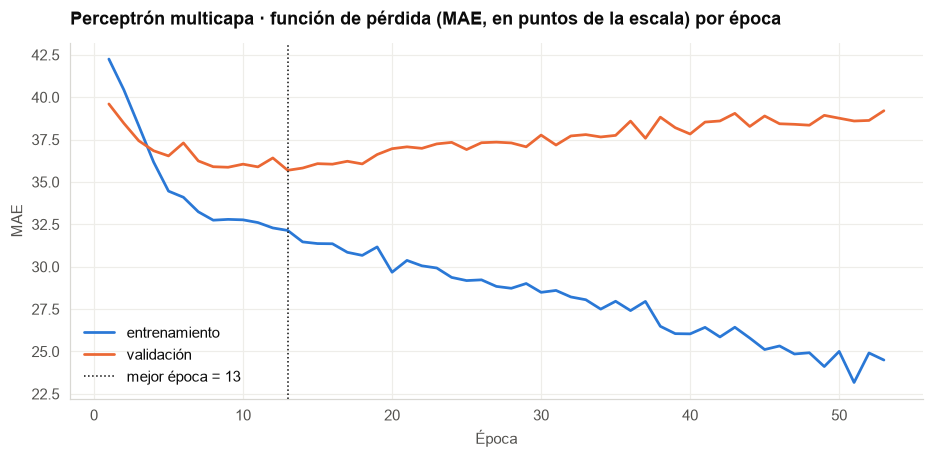

MAE   RMSE    R2  segundos búsqueda  MAE cv
Perceptrón multicapa (PyTorch) train 30.895 38.843 0.409              1.687  35.189
                               val   35.687 44.096 0.203                NaN     NaN
                               test  34.370 42.584 0.310                NaN     NaN

In [6]:
class MLP(nn.Module):
    def __init__(self, n_in, ocultas=(64, 32), p_dropout=0.2):
        super().__init__()
        capas, prev = [], n_in
        for h in ocultas:
            capas += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(p_dropout)]; prev = h
        capas.append(nn.Linear(prev, 1)); self.red = nn.Sequential(*capas)
    def forward(self, x):
        return self.red(x).squeeze(-1)

def a_tensor(X): return torch.tensor(np.asarray(X, dtype=np.float32))
Xt_tr, Xt_va, Xt_te = a_tensor(Xl["train"]), a_tensor(Xl["val"]), a_tensor(Xl["test"])
Y_MEDIA, Y_DESV = float(y_train.mean()), float(y_train.std())          # se escala el objetivo con estadísticos de entrenamiento
yt_tr, yt_va = torch.tensor(((y_train - Y_MEDIA) / Y_DESV).to_numpy(np.float32)), torch.tensor(((y_val - Y_MEDIA) / Y_DESV).to_numpy(np.float32))

def entrenar_mlp(Xt_tr=Xt_tr, yt_tr=yt_tr, Xt_va=Xt_va, yt_va=yt_va, semilla=RANDOM_STATE, epocas=600, paciencia=40, lr=1e-3, wd=1e-3, lote=64):
    torch.manual_seed(semilla); np.random.seed(semilla)
    modelo = MLP(Xt_tr.shape[1]); opt = torch.optim.Adam(modelo.parameters(), lr=lr, weight_decay=wd); perdida = nn.L1Loss()
    historia, mejor, mejor_estado, sin_mejora = [], np.inf, None, 0
    gen = torch.Generator().manual_seed(semilla)
    for epoca in range(epocas):
        modelo.train(); perm = torch.randperm(len(Xt_tr), generator=gen); acumulado = 0.0
        for i in range(0, len(perm), lote):
            idx = perm[i:i + lote]; opt.zero_grad(); loss = perdida(modelo(Xt_tr[idx]), yt_tr[idx]); loss.backward(); opt.step(); acumulado += loss.item() * len(idx)
        modelo.eval()
        with torch.no_grad():
            l_tr, l_va = acumulado / len(perm), perdida(modelo(Xt_va), yt_va).item()
        historia.append((epoca + 1, l_tr * Y_DESV, l_va * Y_DESV))      # pérdidas expresadas en puntos de la escala
        if l_va < mejor - 1e-4: mejor, mejor_estado, sin_mejora = l_va, {k: v.clone() for k, v in modelo.state_dict().items()}, 0
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia: break
    modelo.load_state_dict(mejor_estado); modelo.eval()
    return modelo, pd.DataFrame(historia, columns=["época", "pérdida entrenamiento (MAE)", "pérdida validación (MAE)"])

t0 = time.time(); mlp, historia = entrenar_mlp(); T_MLP = time.time() - t0
mejor_epoca = int(historia["pérdida validación (MAE)"].idxmin()) + 1
class MLPWrapper:
    """Envuelve la red para usar .predict como cualquier estimador de scikit-learn."""
    def __init__(self, modelo): self.modelo = modelo
    def predict(self, X):
        with torch.no_grad(): return self.modelo(a_tensor(X)).numpy() * Y_DESV + Y_MEDIA
mlp_reg = MLPWrapper(mlp)
maes_cv = []      # validación cruzada de 5 pliegues: en cada uno, la parada temprana usa un 15 % interno del entrenamiento y el pliegue retenido solo se evalúa
for i, (tr, va) in enumerate(KFold(5, shuffle=True, random_state=RANDOM_STATE).split(Xt_tr)):
    tr_in, va_in = train_test_split(tr, test_size=0.15, random_state=RANDOM_STATE + i)
    m_cv, _ = entrenar_mlp(Xt_tr[tr_in], yt_tr[tr_in], Xt_tr[va_in], yt_tr[va_in], semilla=RANDOM_STATE + i)
    maes_cv.append(mean_absolute_error(y_train.iloc[va], MLPWrapper(m_cv).predict(Xl["train"].iloc[va])))
reg.update(filas_regresion("Perceptrón multicapa (PyTorch)", mlp_reg, Xl, T_MLP, float(np.mean(maes_cv))))
print(f"MAE de validación cruzada del perceptrón: {np.mean(maes_cv):.2f} ± {np.std(maes_cv):.2f}")
print(f"Épocas ejecutadas: {len(historia)} · mejor época (menor pérdida de validación): {mejor_epoca} · {T_MLP:.0f} s · parámetros: {sum(p.numel() for p in mlp.parameters()):,}")

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(historia["época"], historia["pérdida entrenamiento (MAE)"], color=C_BASE, linewidth=1.8, label="entrenamiento")
ax.plot(historia["época"], historia["pérdida validación (MAE)"], color=C_ACCENT, linewidth=1.8, label="validación")
ax.axvline(mejor_epoca, color=TINTA, linestyle=":", linewidth=1, label=f"mejor época = {mejor_epoca}")
ax.set_title("Perceptrón multicapa · función de pérdida (MAE, en puntos de la escala) por época"); ax.set_xlabel("Época"); ax.set_ylabel("MAE"); ax.legend(frameon=False)
save_fig(fig, "mlp_loss_curve"); plt.show()
display(pd.DataFrame({k: v for k, v in reg.items() if k[0].startswith("Perceptrón")}).T.round(3))

La red tiene **6.657 pesos**, casi diez por cada estudiante de entrenamiento, así que sin frenos memorizaría muy rápido, y la curva de pérdida lo muestra con claridad. En las primeras épocas el error de entrenamiento y el de validación bajan juntos, lo que indica que la red está aprendiendo, y el error de validación llega a su punto más bajo en la **época 13**. A partir de ahí el error de entrenamiento sigue bajando hasta unos 25 puntos, mientras que el de validación sube hasta 39, señal de que la red empezó a memorizar, y por eso la parada temprana detiene el entrenamiento en la época 53 y conserva la versión de la época 13.

Con esa versión la red se equivoca por **34,4 puntos en prueba, con un R² de 0,310**, y por 35,19 en validación cruzada, es decir, queda al mismo nivel de los demás modelos pero no los supera, algo esperable con 700 estudiantes, porque una red necesita muchos más datos para sacarle ventaja a un modelo lineal bien regularizado.

### 4.4 Comparación de los modelos de regresión

Aquí se ponen los seis modelos lado a lado con su error en validación cruzada, que es el criterio para escoger, su error en prueba con su intervalo de confianza y la diferencia entre el error de entrenamiento y el de prueba, que mide cuánto memorizó cada uno. Para leer la tabla vale la pena tener presente una regla, si los intervalos de dos modelos se cruzan en buena parte, con 150 estudiantes de prueba no es posible afirmar que uno sea mejor que el otro.

MAE   RMSE    R2  segundos búsqueda  MAE cv
modelo                         parte                                               
Ridge (referencia)             train 33.267 40.411 0.361                NaN  34.765
                               val   36.593 44.400 0.192                NaN     NaN
                               test  35.003 42.723 0.305                NaN     NaN
Lasso                          train 32.718 39.825 0.379              3.908  34.934
                               val   36.942 44.807 0.177                NaN     NaN
                               test  35.221 43.272 0.287                NaN     NaN
ElasticNet                     train 33.029 40.135 0.369              0.545  34.763
                               val   36.728 44.517 0.187                NaN     NaN
                               test  34.969 42.749 0.304                NaN     NaN
Random Forest                  train 26.345 32.003 0.599             21.286  34.615
                               val   35.244 42.710 0.252                NaN     NaN
                               test  33.809 42.447 0.314                NaN     NaN
Gradient Boosting              train 30.277 37.113 0.461             13.782  34.525
                               val   36.751 44.114 0.202                NaN     NaN
                               test  34.328 43.306 0.286                NaN     NaN
Perceptrón multicapa (PyTorch) train 30.895 38.843 0.409              1.687  35.189
                               val   35.687 44.096 0.203                NaN     NaN
                               test  34.370 42.584 0.310                NaN     NaN

,MAE cv (train),MAE test,IC 95 % MAE,RMSE test,R2 test,sobreajuste (MAE test − train),mejora vs. media (%)
modelo,,,,,,,
Random Forest,34.615,33.809,"[29.8, 37.9]",42.447,0.314,7.464,19.889
Gradient Boosting,34.525,34.328,"[30.2, 39.0]",43.306,0.286,4.051,18.660
Perceptrón multicapa (PyTorch),35.189,34.370,"[30.5, 38.6]",42.584,0.310,3.474,18.561
ElasticNet,34.763,34.969,"[31.0, 39.1]",42.749,0.304,1.941,17.141
Ridge (referencia),34.765,35.003,"[31.2, 39.1]",42.723,0.305,1.736,17.061
Lasso,34.934,35.221,"[31.2, 39.3]",43.272,0.287,2.503,16.544


Mejor modelo de regresión por validación cruzada: Gradient Boosting


Figura guardada: assets\images\data\regression_comparison.png


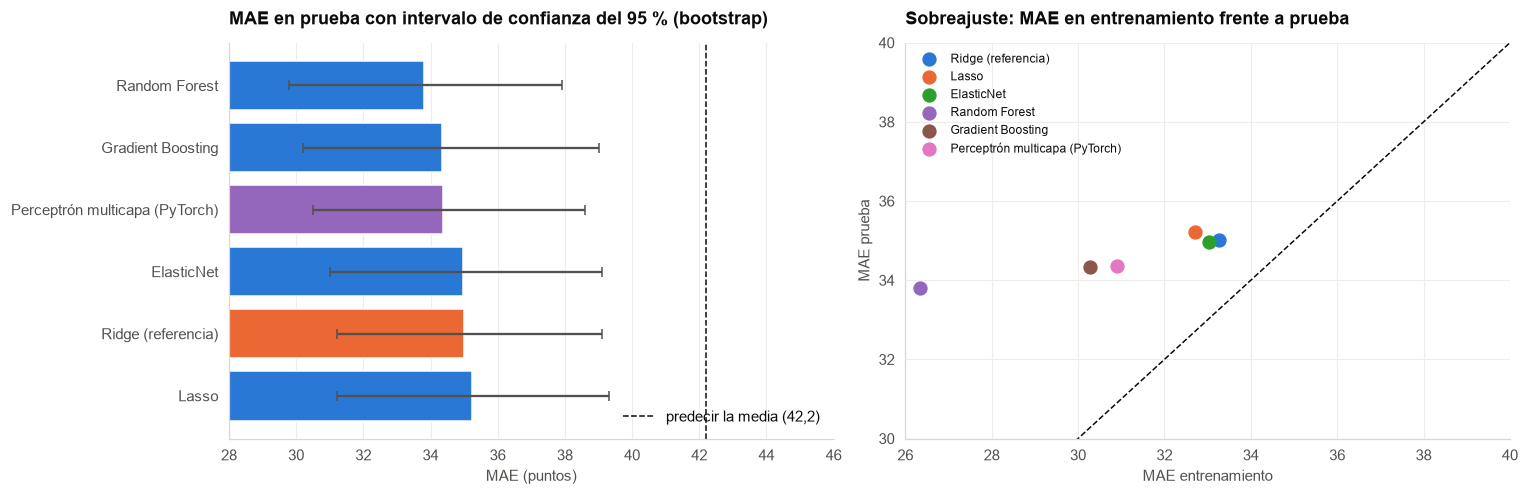

In [7]:
tabla_reg = pd.DataFrame(reg).T; tabla_reg.index.names = ["modelo", "parte"]
tabla_reg.to_csv(PROCESSED_DIR / "metricas_fase3_regresion.csv")
display(tabla_reg.round(3))

modelos_reg = {"Ridge (referencia)": (ridge_ref, Xl), "Lasso": (lasso, Xl), "ElasticNet": (enet, Xl), "Random Forest": (rf_reg, Xa),
               "Gradient Boosting": (gb_reg, Xa), "Perceptrón multicapa (PyTorch)": (mlp_reg, Xl)}
resumen_reg = []
for nombre, (m, rep) in modelos_reg.items():
    pred = m.predict(rep["test"]); lo, hi = ic_bootstrap(y_test, pred, mean_absolute_error)
    tr = tabla_reg.loc[(nombre, "train")]; te = tabla_reg.loc[(nombre, "test")]
    resumen_reg.append({"modelo": nombre, "MAE cv (train)": tr["MAE cv"], "MAE test": te["MAE"], "IC 95 % MAE": f"[{lo:.1f}, {hi:.1f}]", "RMSE test": te["RMSE"],
                        "R2 test": te["R2"], "sobreajuste (MAE test − train)": te["MAE"] - tr["MAE"], })
resumen_reg = pd.DataFrame(resumen_reg).set_index("modelo").sort_values("MAE test")
resumen_reg["mejora vs. media (%)"] = (1 - resumen_reg["MAE test"] / 42.203) * 100
display(resumen_reg.round(3))
MEJOR_REG = resumen_reg["MAE cv (train)"].idxmin(); print(f"Mejor modelo de regresión por validación cruzada: {MEJOR_REG}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
orden = resumen_reg.index[::-1]; colores = [C_ACCENT if m.startswith("Ridge") else (C_MORADO if m.startswith("Perceptrón") else C_BASE) for m in orden]
ic = np.array([[float(x) for x in resumen_reg.loc[m, "IC 95 % MAE"].strip("[]").split(",")] for m in orden])
axes[0].barh(orden, resumen_reg.loc[orden, "MAE test"], color=colores, xerr=[resumen_reg.loc[orden, "MAE test"] - ic[:, 0], ic[:, 1] - resumen_reg.loc[orden, "MAE test"]], capsize=3, ecolor=GRIS)
axes[0].axvline(42.203, color=TINTA, linestyle="--", linewidth=1, label="predecir la media (42,2)"); axes[0].set_xlim(28, 46)
axes[0].set_title("MAE en prueba con intervalo de confianza del 95 % (bootstrap)"); axes[0].set_xlabel("MAE (puntos)"); axes[0].legend(frameon=False, loc="lower right"); axes[0].grid(axis="y", visible=False)
for (nombre, (m, rep)), color in zip(modelos_reg.items(), PALETTE):
    axes[1].scatter(tabla_reg.loc[(nombre, "train"), "MAE"], tabla_reg.loc[(nombre, "test"), "MAE"], s=70, color=color, label=nombre)
lim = [26, 40]; axes[1].plot(lim, lim, color=TINTA, linestyle="--", linewidth=1); axes[1].set_xlim(lim); axes[1].set_ylim(30, 40)
axes[1].set_title("Sobreajuste: MAE en entrenamiento frente a prueba"); axes[1].set_xlabel("MAE entrenamiento"); axes[1].set_ylabel("MAE prueba"); axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout(); save_fig(fig, "regression_comparison"); plt.show()

La tabla deja una conclusión clara, los seis modelos rinden casi igual, con errores en prueba entre **33,8 y 35,2 puntos** e intervalos de confianza de unos cuatro puntos hacia cada lado, por ejemplo de 29,8 a 37,9 para el Random Forest y de 31,2 a 39,1 para Ridge, que se cruzan casi por completo, de modo que con 150 estudiantes de prueba no se puede afirmar que uno sea mejor que otro. En validación cruzada, que es el criterio acordado, gana el **Gradient Boosting** con 34,53 puntos, seguido del Random Forest con 34,62, ElasticNet y Ridge con 34,76 y, de último, la red con 35,19, y el Gradient Boosting se equivoca un **18,7 % menos** que predecir el promedio, frente al 17,1 % de Ridge.

El gráfico de la derecha muestra cuánto memoriza cada modelo, los lineales quedan pegados a la diagonal con diferencias de 1,7 a 2,5 puntos entre entrenamiento y prueba, la red y el *boosting* quedan en una zona intermedia con 3,5 y 4,1, y el Random Forest queda lejos, con 7,5.

La mejora es pequeña porque el límite lo ponen los datos y no el algoritmo, ya que el contexto del hogar y del colegio explica cerca del 30 % de las diferencias de puntaje y el 70 % restante depende de factores que el cuestionario no mide, como el esfuerzo, la motivación o la calidad de cada aula. Entre modelos equivalentes se prefiere el más estable, así que el **Gradient Boosting** queda como modelo final, y Ridge se mantiene como una alternativa más fácil de explicar que pierde menos de un punto.

## 5. ¿Se puede predecir mejor el nivel de desempeño?

### 5.1 Random Forest y máquina de soporte vectorial, con KNN como contraste

Para decidir si un estudiante queda en el nivel bajo, medio o alto se prueban tres algoritmos que razonan de forma distinta. El **Random Forest** es el mismo bosque de árboles de la sección 4, que ahora vota por una clase en lugar de promediar un puntaje, la **máquina de soporte vectorial (SVM)** busca las fronteras que separan las clases dejando el mayor margen posible entre ellas, y con el núcleo RBF esas fronteras pueden ser curvas, aunque como depende de la escala trabaja con los datos estandarizados, y el **KNN**, o vecinos más cercanos, clasifica a cada estudiante según la clase más común entre los estudiantes que más se le parecen. Los hiperparámetros de cada uno se eligen con validación cruzada buscando el mejor **F1 macro**, y a la SVM se le pide que calcule probabilidades para poder medir su AUC-ROC.

In [8]:
cv_clf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
clf = {}
def filas_clasificacion(nombre, modelo, rep, tiempo=np.nan, cv_score=np.nan):
    out = {}
    for p in ["train", "val", "test"]:
        out[(nombre, p)] = evaluar_clasificacion(partes[p][2], modelo.predict(rep[p]), modelo.predict_proba(rep[p]))
    out[(nombre, "train")]["segundos búsqueda"] = tiempo; out[(nombre, "train")]["F1 cv"] = cv_score
    return out

clf.update(filas_clasificacion("Regresión logística (referencia)", logistica_ref, Xl, cv_score=cross_val_score(logistica_ref, Xl["train"], c_train, cv=cv_clf, scoring="f1_macro").mean()))
b_rfc, t = ajustar(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS, class_weight="balanced"),
                   {"n_estimators": [200, 400], "max_depth": [None, 4, 6, 8, 12], "min_samples_leaf": [2, 5, 10, 20], "max_features": ["sqrt", 0.3, 0.5]},
                   Xa["train"], c_train, cv_clf, "f1_macro", n_iter=20)
rf_clf = b_rfc.best_estimator_; clf.update(filas_clasificacion("Random Forest", rf_clf, Xa, t, b_rfc.best_score_))
b_svm, t = ajustar(SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE), {"C": [0.1, 0.3, 1, 3, 10], "gamma": ["scale", 0.003, 0.01, 0.03]},
                   Xl["train"], c_train, cv_clf, "f1_macro")
svm_clf = b_svm.best_estimator_; clf.update(filas_clasificacion("SVM (RBF)", svm_clf, Xl, t, b_svm.best_score_))
b_knn, t = ajustar(KNeighborsClassifier(), {"n_neighbors": [5, 11, 21, 31, 51], "weights": ["uniform"]}, Xl["train"], c_train, cv_clf, "f1_macro")
knn_clf = b_knn.best_estimator_; clf.update(filas_clasificacion("KNN", knn_clf, Xl, t, b_knn.best_score_))
print("Random Forest:", b_rfc.best_params_); print("SVM:", b_svm.best_params_); print("KNN:", b_knn.best_params_)
tabla_clf = pd.DataFrame(clf).T; tabla_clf.index.names = ["modelo", "parte"]; tabla_clf.to_csv(PROCESSED_DIR / "metricas_fase3_clasificacion.csv")
display(tabla_clf.round(3))

Random Forest: {'n_estimators': 400, 'min_samples_leaf': 10, 'max_features': 0.3, 'max_depth': 12}
SVM: {'C': 0.3, 'gamma': 'scale'}
KNN: {'n_neighbors': 51, 'weights': 'uniform'}


exactitud  precisión macro  exhaustividad macro  F1 macro  AUC-ROC (ovr)  segundos búsqueda  F1 cv
modelo                           parte                                                                                                    
Regresión logística (referencia) train      0.531            0.540                0.531     0.532          0.701                NaN  0.507
                                 val        0.493            0.511                0.491     0.487          0.655                NaN    NaN
                                 test       0.480            0.509                0.480     0.482          0.664                NaN    NaN
Random Forest                    train      0.684            0.687                0.685     0.680          0.872             31.912  0.503
                                 val        0.533            0.530                0.532     0.525          0.685                NaN    NaN
                                 test       0.473            0.462                0.473     0.463          0.693                NaN    NaN
SVM (RBF)                        train      0.601            0.608                0.601     0.603          0.785              6.316  0.508
                                 val        0.480            0.493                0.478     0.473          0.663                NaN    NaN
                                 test       0.500            0.515                0.500     0.498          0.680                NaN    NaN
KNN                              train      0.519            0.524                0.519     0.518          0.712              0.309  0.482
                                 val        0.440            0.447                0.440     0.442          0.634                NaN    NaN
                                 test       0.500            0.506                0.500     0.502          0.681                NaN    NaN

Otra vez ganan las versiones sencillas, pues el Random Forest elegido exige al menos 10 estudiantes por hoja, la SVM usa un margen amplio (`C` igual a 0,3) y el KNN funciona mejor mirando **51 vecinos**, el máximo que se probó, lo que quiere decir que entre más promedia, mejor le va. En validación cruzada los cuatro clasificadores quedan empatados, con F1 macro de 0,507 para la regresión logística, 0,503 para el Random Forest, **0,508 para la SVM** y 0,482 para el KNN, y en el grupo de prueba el F1 va desde 0,463 en el Random Forest hasta 0,502 en el KNN, con la SVM en 0,498 y la regresión logística en 0,482. El Random Forest es el que más memoriza, con 0,680 en entrenamiento frente a 0,463 en prueba, y la SVM lo hace en menor medida, con 0,603 frente a 0,498.

### 5.2 Comparación, matrices de confusión y curvas ROC

Los cuatro clasificadores se comparan en el grupo de prueba. Las **matrices de confusión** muestran en qué se equivoca cada uno, con especial atención al nivel medio, y las **curvas ROC** del mejor modelo muestran qué tan fácil resulta separar cada nivel del resto, de modo que entre más se acerque la curva a la esquina superior izquierda, mejor, mientras que la diagonal punteada representa el azar.

,F1 cv (train),F1 macro test,IC 95 % F1,exactitud test,AUC-ROC test,sobreajuste (F1 train − test)
modelo,,,,,,
KNN,0.482,0.502,"[0.42, 0.58]",0.500,0.681,0.017
SVM (RBF),0.508,0.498,"[0.42, 0.57]",0.500,0.680,0.104
Regresión logística (referencia),0.507,0.482,"[0.39, 0.56]",0.480,0.664,0.050
Random Forest,0.503,0.463,"[0.38, 0.54]",0.473,0.693,0.217


Mejor clasificador por validación cruzada: SVM (RBF)


Figura guardada: assets\images\data\classification_confusion.png


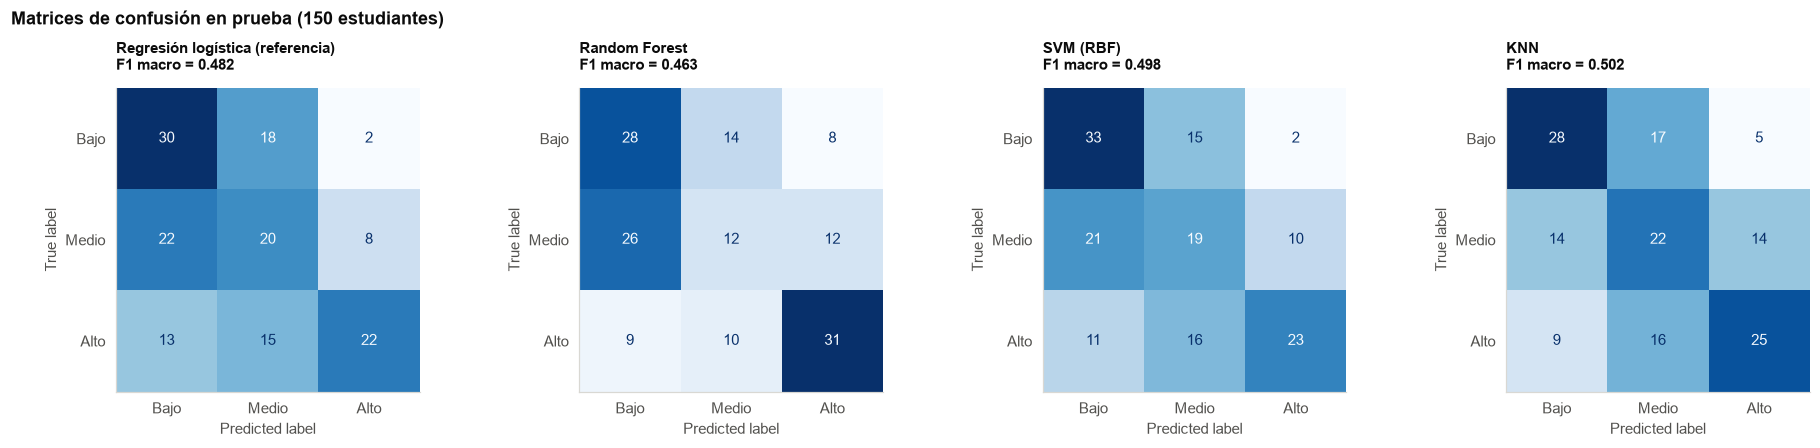

Figura guardada: assets\images\data\classification_roc.png


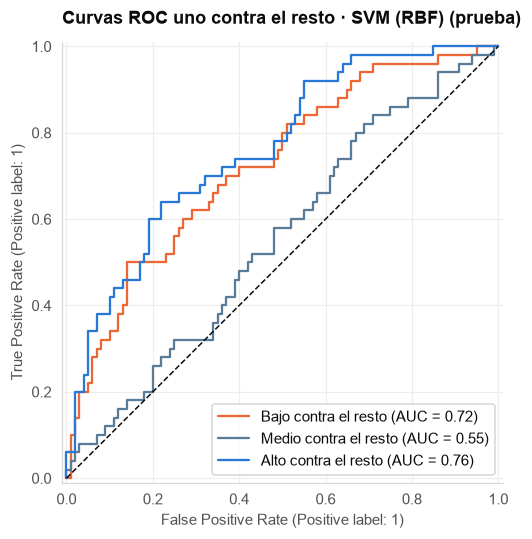

Métricas por clase del mejor clasificador (SVM (RBF)):


,Bajo,Medio,Alto
precisión,0.508,0.380,0.657
exhaustividad,0.660,0.380,0.460
F1,0.574,0.380,0.541


In [9]:
modelos_clf = {"Regresión logística (referencia)": (logistica_ref, Xl), "Random Forest": (rf_clf, Xa), "SVM (RBF)": (svm_clf, Xl), "KNN": (knn_clf, Xl)}
f1m = lambda a, b: f1_score(a, b, average="macro")
resumen_clf = []
for nombre, (m, rep) in modelos_clf.items():
    pred = m.predict(rep["test"]); lo, hi = ic_bootstrap(c_test, pred, f1m)
    tr, te = tabla_clf.loc[(nombre, "train")], tabla_clf.loc[(nombre, "test")]
    resumen_clf.append({"modelo": nombre, "F1 cv (train)": tr["F1 cv"], "F1 macro test": te["F1 macro"], "IC 95 % F1": f"[{lo:.2f}, {hi:.2f}]", "exactitud test": te["exactitud"],
                        "AUC-ROC test": te["AUC-ROC (ovr)"], "sobreajuste (F1 train − test)": tr["F1 macro"] - te["F1 macro"]})
resumen_clf = pd.DataFrame(resumen_clf).set_index("modelo").sort_values("F1 macro test", ascending=False); display(resumen_clf.round(3))
MEJOR_CLF = resumen_clf["F1 cv (train)"].idxmax(); print(f"Mejor clasificador por validación cruzada: {MEJOR_CLF}")

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (nombre, (m, rep)) in zip(axes, modelos_clf.items()):
    ConfusionMatrixDisplay(confusion_matrix(c_test, m.predict(rep["test"]), labels=CLASES), display_labels=CLASES).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{nombre}\nF1 macro = {tabla_clf.loc[(nombre, 'test'), 'F1 macro']:.3f}", fontsize=10); ax.grid(False)
fig.suptitle("Matrices de confusión en prueba (150 estudiantes)", x=0.01, ha="left", fontweight="bold"); fig.tight_layout(); save_fig(fig, "classification_confusion"); plt.show()

mejor_m, mejor_rep = modelos_clf[MEJOR_CLF]
proba = mejor_m.predict_proba(mejor_rep["test"]); clases_modelo = list(mejor_m.classes_)
fig, ax = plt.subplots(figsize=(6.5, 5.2))
for k, color in zip(CLASES, [C_ACCENT, C_NEU, C_BASE]):
    RocCurveDisplay.from_predictions((c_test == k).astype(int), proba[:, clases_modelo.index(k)], name=f"{k} contra el resto", ax=ax, curve_kwargs={"color": color})
ax.plot([0, 1], [0, 1], color=TINTA, linestyle="--", linewidth=1); ax.set_title(f"Curvas ROC uno contra el resto · {MEJOR_CLF} (prueba)")
save_fig(fig, "classification_roc"); plt.show()
por_clase = pd.DataFrame({"precisión": precision_score(c_test, mejor_m.predict(mejor_rep["test"]), labels=CLASES, average=None),
                          "exhaustividad": recall_score(c_test, mejor_m.predict(mejor_rep["test"]), labels=CLASES, average=None),
                          "F1": f1_score(c_test, mejor_m.predict(mejor_rep["test"]), labels=CLASES, average=None)}, index=CLASES)
print(f"Métricas por clase del mejor clasificador ({MEJOR_CLF}):"); display(por_clase.round(3).T)

Por validación cruzada gana la **SVM**, con un F1 de 0,508, aunque en la práctica empata con la regresión logística, que obtiene 0,507, y los intervalos de confianza en prueba, de unos 0,08 hacia cada lado, se cruzan por completo. En el grupo de prueba la SVM alcanza un **F1 macro de 0,498, una exactitud de 0,500 y un AUC-ROC de 0,680**, 1,6 puntos de F1 por encima de la referencia. Un detalle curioso es que el Random Forest tiene el mejor AUC, 0,693, pero el peor F1, 0,463, lo que significa que ordena bien a los estudiantes de más a menos probable pero, a la hora de asignarles uno de los tres niveles, acierta menos.

Las matrices de confusión repiten lo que se vio en el cuaderno 02, los extremos se distinguen y el nivel medio no, ya que la SVM encuentra al 66 % de los estudiantes de nivel bajo y al 46 % de los de nivel alto, pero solo al **38 % de los de nivel medio**, y de cada diez estudiantes que clasifica como de nivel medio, seis son en realidad de nivel bajo o alto. Las curvas ROC lo confirman, pues separar el nivel bajo del resto, con un AUC de 0,72, y el nivel alto del resto, con 0,76, resulta razonable, mientras que el nivel medio frente al resto, con 0,55, apenas supera el azar.

La razón no está en el algoritmo, sino en que dividir un puntaje continuo en tres tercios pone fronteras entre estudiantes casi iguales, y el contexto no alcanza a distinguir a uno de 220 puntos de otro de 225. Para un sistema de alertas tempranas tiene más sentido preguntar únicamente si un estudiante está en riesgo de quedar en el nivel bajo, con un AUC de 0,72, o bien usar el modelo de regresión y fijar el umbral después.

## 6. ¿Existen grupos naturales de estudiantes?

### 6.1 Qué se agrupa y cómo se elige el número de grupos con K-means

En esta parte no se predice nada, sino que se buscan grupos de estudiantes con resultados parecidos usando los cinco puntajes por área y la edad, y aquí sí es válido usar los puntajes porque no se está prediciendo el puntaje global. Hay que tener en cuenta que las áreas van muy de la mano, pues quien obtiene un buen resultado en matemáticas suele obtenerlo también en lectura, así que si se agrupa con los puntajes tal como vienen, los grupos van a reflejar sobre todo el **nivel** general de cada estudiante. Para ver las **fortalezas** se usa además el **perfil relativo**, que es cada puntaje menos el promedio del propio estudiante y que permite distinguir a quien sobresale en inglés de quien sobresale en lectura, sin importar si su nivel general es alto o bajo.

**K-means** reparte a los estudiantes en K grupos alrededor de K centros, y para escoger cuántos grupos usar se prueban valores de 2 a 8 con dos criterios. El primero es el **método del codo**, que se basa en que a medida que se agregan grupos la dispersión dentro de cada uno disminuye, pero llega un punto en el que agregar más grupos ya casi no mejora nada, y ese quiebre sugiere el número adecuado. El segundo es la **silueta**, que va de −1 a 1 y mide qué tan cerca está cada estudiante de su propio grupo en comparación con el grupo vecino, de modo que valores entre 0,26 y 0,50 indican grupos débiles pero reales. También se revisan los índices de Davies-Bouldin, que es mejor entre más bajo, y de Calinski-Harabasz, que es mejor entre más alto.

La regla de decisión se fija antes de ver los resultados, se toma el número de grupos con la mejor silueta, salvo que con ese número solo se separe un grupo pequeño de menos del 5 % de los estudiantes, porque en ese caso la silueta estaría midiendo qué tan distintos son esos pocos casos y no la estructura del conjunto, y entonces se usa el mejor valor de Calinski-Harabasz.

K-means sobre nivel (puntajes + edad):


K,2,3,4,5,6,7,8
inercia,"2,899.827","1,656.212","1,369.152","1,164.179","1,065.093",961.842,891.945
silueta,0.805,0.381,0.317,0.256,0.209,0.234,0.209
Davies-Bouldin,0.325,0.772,0.993,1.042,1.210,1.068,1.174
Calinski-Harabasz,850.136,"1,117.811",970.153,898.661,803.530,758.500,711.503
tamaño mínimo,20.000,20.000,20.000,19.000,19.000,16.000,12.000


K-means sobre perfil relativo (áreas − promedio):


K,2,3,4,5,6,7,8
inercia,"4,018.342","3,428.339","3,047.661","2,761.663","2,523.229","2,365.520","2,241.631"
silueta,0.189,0.179,0.176,0.177,0.176,0.177,0.172
Davies-Bouldin,1.853,1.586,1.503,1.438,1.390,1.386,1.370
Calinski-Harabasz,243.806,228.534,212.689,201.613,195.140,184.317,174.382
tamaño mínimo,500.000,297.000,210.000,167.000,134.000,106.000,95.000


Figura guardada: assets\images\data\kmeans_elbow_silhouette.png


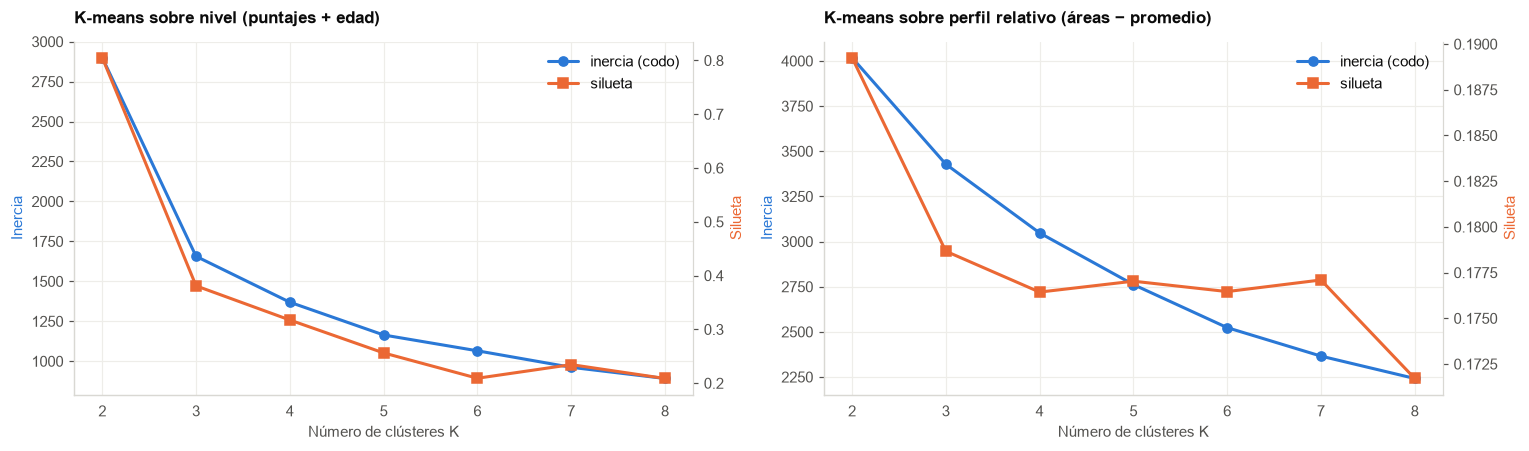

K elegido: nivel = 3 (K = 2 solo aísla a 20 estudiantes, por lo que se usa el máximo de Calinski-Harabasz) · perfil relativo = 2 (máximo de silueta)


In [10]:
VARS_NIVEL = AREA_COLS + ["edad"]
Xc = df[VARS_NIVEL].astype(float); Xc = Xc.fillna(Xc.median())
Z_nivel = RobustScaler().fit_transform(Xc)
perfil = df[AREA_COLS].astype(float); perfil = perfil.fillna(perfil.median())
Z_perfil = StandardScaler().fit_transform(perfil.sub(perfil.mean(axis=1), axis=0))

def barrido_kmeans(Z, ks=range(2, 9)):
    filas = []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Z)
        filas.append({"K": k, "inercia": km.inertia_, "silueta": silhouette_score(Z, km.labels_), "Davies-Bouldin": davies_bouldin_score(Z, km.labels_),
                      "Calinski-Harabasz": calinski_harabasz_score(Z, km.labels_), "tamaño mínimo": np.bincount(km.labels_).min()})
    return pd.DataFrame(filas).set_index("K")

barrido = {"nivel (puntajes + edad)": barrido_kmeans(Z_nivel), "perfil relativo (áreas − promedio)": barrido_kmeans(Z_perfil)}
for nombre, b in barrido.items():
    print(f"K-means sobre {nombre}:"); display(b.round(3).T)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, (nombre, b) in zip(axes, barrido.items()):
    ax.plot(b.index, b["inercia"], marker="o", color=C_BASE, linewidth=2, label="inercia (codo)"); ax.set_xlabel("Número de clústeres K"); ax.set_ylabel("Inercia", color=C_BASE)
    ax2 = ax.twinx(); ax2.plot(b.index, b["silueta"], marker="s", color=C_ACCENT, linewidth=2, label="silueta"); ax2.set_ylabel("Silueta", color=C_ACCENT); ax2.grid(False); ax2.spines["right"].set_visible(True)
    ax.set_title(f"K-means sobre {nombre}", fontsize=11); ax.set_xticks(list(b.index))
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, frameon=False, loc="upper right")
fig.tight_layout(); save_fig(fig, "kmeans_elbow_silhouette"); plt.show()
b_niv = barrido["nivel (puntajes + edad)"]
K_NIVEL = int(b_niv["Calinski-Harabasz"].idxmax()) if b_niv.loc[2, "tamaño mínimo"] < 0.05 * len(df) else int(b_niv["silueta"].idxmax())
K_PERFIL = int(barrido["perfil relativo (áreas − promedio)"]["silueta"].idxmax())
print(f"K elegido: nivel = {K_NIVEL} (K = 2 solo aísla a {int(b_niv.loc[2, 'tamaño mínimo'])} estudiantes, por lo que se usa el máximo de Calinski-Harabasz) · perfil relativo = {K_PERFIL} (máximo de silueta)")

Al agrupar por **nivel**, la mejor silueta, de 0,805, se obtiene con dos grupos, pero ese corte solo separa a **20 estudiantes**, de modo que la silueta está premiando lo distintos que son esos pocos adultos y no la forma del conjunto. Siguiendo la regla fijada, se pasa entonces al mejor valor de Calinski-Harabasz, que señala **tres grupos**, y allí también aparece el codo, ya que la dispersión baja de 2.900 a 1.656 al pasar de dos a tres grupos y luego solo hasta 1.369, con una silueta de 0,381, que corresponde a grupos débiles pero reales.

Al agrupar por **perfil relativo**, la silueta es baja y casi igual para cualquier número de grupos, entre 0,17 y 0,19, con un máximo leve en **dos grupos**, lo que significa que una vez descontado el nivel general los estudiantes no forman grupos marcados según sus fortalezas, sino un continuo con una dirección principal. Ese es un hallazgo en sí mismo, pues lo que más diferencia a los estudiantes es su nivel general, ya que las áreas van muy de la mano.

### 6.2 Agrupamiento jerárquico y comparación con K-means

Para comprobar si los grupos dependen del método se usa un segundo algoritmo, el **agrupamiento jerárquico aglomerativo**, que arranca con cada estudiante como un grupo y va uniendo los dos grupos más parecidos, con el criterio de **Ward**, que une los que menos aumentan la dispersión, hasta que todos quedan en uno solo. El **dendrograma** dibuja ese proceso como un árbol en el que las uniones más altas juntan grupos muy distintos, y cortarlo a cierta altura da como resultado los grupos. La coincidencia con K-means se mide con el **índice de Rand ajustado**, que vale 1 si los dos métodos agrupan igual y 0 si solo coinciden por azar.

También se prueba **DBSCAN**, que forma grupos donde hay muchos estudiantes juntos y deja como ruido a los que quedan aislados. No es la segmentación principal, sino una forma de comprobar si los adultos de mayor edad quedan como casos aislados en lugar de formar un grupo propio.

Figura guardada: assets\images\data\hierarchical_dendrogram.png


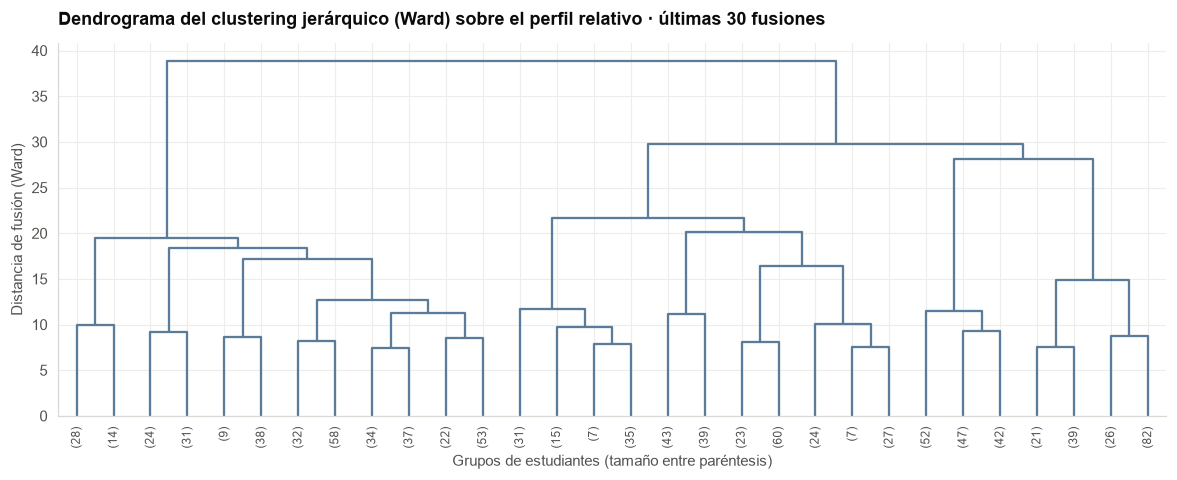

K,2,3,4,5,6,7,8
silueta,0.140,0.119,0.105,0.113,0.113,0.120,0.122
Davies-Bouldin,2.072,2.097,1.674,1.693,1.640,1.602,1.594
tamaño mínimo,380.000,309.000,141.000,88.000,82.000,42.000,42.000


Jerárquico: K = 2 por silueta · coincidencia con K-means (K = 2) según el índice de Rand ajustado: 0.399
DBSCAN (eps = 0.85, percentil 90 de la distancia al 5.º vecino): 2 clúster(es) y 50 estudiantes como ruido; edad media del ruido 24.3 años frente a 17.6 del resto


In [11]:
enlace = linkage(Z_perfil, method="ward")
fig, ax = plt.subplots(figsize=(13, 4.4))
dendrogram(enlace, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=8, color_threshold=0, above_threshold_color=C_NEU, ax=ax)
ax.set_title("Dendrograma del clustering jerárquico (Ward) sobre el perfil relativo · últimas 30 fusiones"); ax.set_ylabel("Distancia de fusión (Ward)"); ax.set_xlabel("Grupos de estudiantes (tamaño entre paréntesis)")
save_fig(fig, "hierarchical_dendrogram"); plt.show()

filas = []
for k in range(2, 9):
    etiquetas = fcluster(enlace, k, criterion="maxclust")
    filas.append({"K": k, "silueta": silhouette_score(Z_perfil, etiquetas), "Davies-Bouldin": davies_bouldin_score(Z_perfil, etiquetas), "tamaño mínimo": np.bincount(etiquetas)[1:].min()})
jer = pd.DataFrame(filas).set_index("K"); display(jer.round(3).T)
K_JER = int(jer["silueta"].idxmax())
km_perfil = KMeans(n_clusters=K_PERFIL, n_init=20, random_state=RANDOM_STATE).fit(Z_perfil)
agg_perfil = AgglomerativeClustering(n_clusters=K_JER, linkage="ward").fit(Z_perfil)
print(f"Jerárquico: K = {K_JER} por silueta · coincidencia con K-means (K = {K_PERFIL}) según el índice de Rand ajustado: {adjusted_rand_score(km_perfil.labels_, agg_perfil.labels_):.3f}")

vecinos = np.sort(np.linalg.norm(Z_nivel[:, None, :] - Z_nivel[None, :, :], axis=2), axis=1)[:, 5]
eps = float(np.percentile(vecinos, 90))
db = DBSCAN(eps=eps, min_samples=6).fit(Z_nivel)
ruido = db.labels_ == -1
print(f"DBSCAN (eps = {eps:.2f}, percentil 90 de la distancia al 5.º vecino): {len(set(db.labels_)) - int(ruido.any())} clúster(es) y {ruido.sum()} estudiantes como ruido; "
      f"edad media del ruido {df.loc[ruido, 'edad_original'].mean():.1f} años frente a {df.loc[~ruido, 'edad_original'].mean():.1f} del resto")

El dendrograma muestra dos ramas grandes de tamaño parecido y, por debajo, uniones cada vez más bajas sin saltos bruscos, que es la imagen de un continuo más que de grupos bien separados. El corte jerárquico también obtiene su mejor silueta con **dos grupos**, con un valor de 0,140, algo menor que el de K-means, de 0,189, y el índice de Rand ajustado entre los dos métodos es de **0,40**, es decir, coinciden en la idea principal, que es la oposición entre lectura e inglés, pero reparten de forma distinta a los muchos estudiantes que quedan cerca de la frontera.

DBSCAN hace exactamente lo que se quería comprobar, pues deja como ruido a **50 estudiantes con una edad media de 24,3 años**, frente a 17,6 del resto, y no crea un grupo aparte para ellos. Para el uso práctico se prefiere K-means, porque sus grupos son más compactos y sus centros se pueden describir y reutilizar en el tablero.

### 6.3 Quiénes son los grupos y para qué sirven

Un grupo solo es útil si se puede describir y si sirve para tomar decisiones, así que para cada uno se calcula su **perfil**, con el número de estudiantes, sus puntajes por área, su edad y su contexto, es decir, el tipo y la jornada del colegio, el acceso a internet en la casa y el nivel de desempeño. Los grupos se dibujan en un plano formado por las dos primeras **componentes principales**, una forma de resumir las seis variables en dos ejes sin perder mucha información, y cada grupo se traduce en algo accionable, como a quién dirigir un refuerzo, dónde están los adultos de jornadas nocturnas o qué grupo concentra a los colegios oficiales.

Segmentación por nivel (K-means sobre puntajes y edad):


cluster_nivel,0,1,2
estudiantes,423.000,20.000,557.000
puntaje global,298.000,189.800,214.200
edad,17.000,39.300,17.800
lectura_critica,62.000,40.400,46.600
matematicas,60.500,34.700,43.100
sociales_ciudadanas,57.900,40.200,39.700
c_naturales,57.900,37.500,42.300
ingles,60.100,35.100,42.000
% colegio oficial,67.600,60.000,85.500
% jornada nocturna o sabatina,2.400,100.000,14.400


Segmentación por perfil relativo (K-means sobre áreas menos el promedio del estudiante):


cluster_perfil,0,1
estudiantes,500.000,500.000
puntaje global,253.100,245.200
edad,18.200,17.600
lectura_critica,54.700,51.200
matematicas,51.100,49.500
sociales_ciudadanas,49.900,44.900
c_naturales,48.900,48.700
ingles,44.300,54.900
% colegio oficial,80.400,74.400
% jornada nocturna o sabatina,13.800,8.200


Perfil relativo medio de cada clúster (puntos por encima o por debajo del promedio del propio estudiante):


cluster_perfil,0,1
lectura_critica,4.900,1.400
matematicas,1.300,-0.400
sociales_ciudadanas,0.100,-4.900
c_naturales,-0.800,-1.100
ingles,-5.500,5.100


Figura guardada: assets\images\data\clusters_pca.png


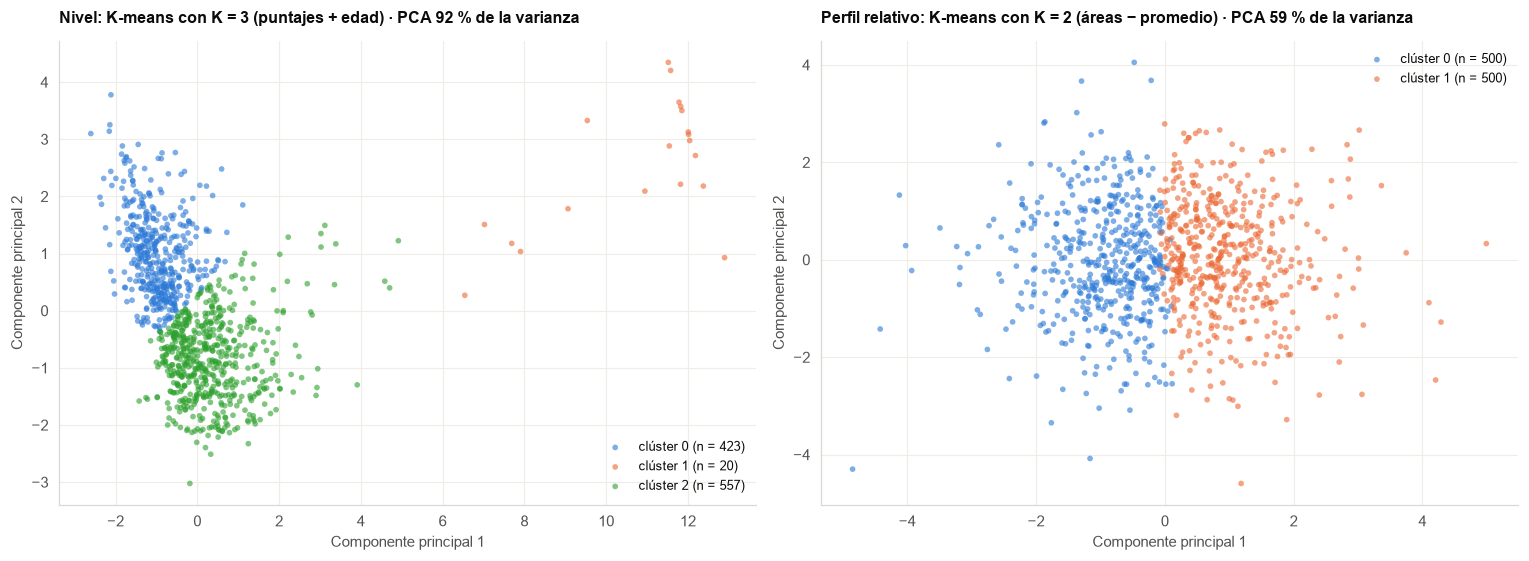

In [12]:
km_nivel = KMeans(n_clusters=K_NIVEL, n_init=20, random_state=RANDOM_STATE).fit(Z_nivel)
seg = df[["punt_global", "nivel_desempeno", "edad_original", "cole_naturaleza", "cole_jornada", "fami_estratovivienda", "fami_tieneinternet", "region"] + AREA_COLS].copy()
seg["cluster_nivel"] = km_nivel.labels_; seg["cluster_perfil"] = km_perfil.labels_

def perfil_de(col):
    g = seg.groupby(col)
    p = pd.DataFrame({"estudiantes": g.size(), "puntaje global": g["punt_global"].mean(), "edad": g["edad_original"].mean(),
                      **{a.replace("punt_", ""): g[a].mean() for a in AREA_COLS},
                      "% colegio oficial": g["cole_naturaleza"].apply(lambda s: (s == "OFICIAL").mean() * 100),
                      "% jornada nocturna o sabatina": g["cole_jornada"].apply(lambda s: s.isin(["NOCHE", "SABATINA"]).mean() * 100),
                      "% con internet": g["fami_tieneinternet"].apply(lambda s: (s == "Si").mean() * 100),
                      "% nivel alto": g["nivel_desempeno"].apply(lambda s: (s == "Alto").mean() * 100)})
    return p.round(1)
print("Segmentación por nivel (K-means sobre puntajes y edad):"); display(perfil_de("cluster_nivel").T)
print("Segmentación por perfil relativo (K-means sobre áreas menos el promedio del estudiante):"); display(perfil_de("cluster_perfil").T)
fortalezas = (perfil.sub(perfil.mean(axis=1), axis=0).groupby(seg["cluster_perfil"]).mean()).round(1)
fortalezas.columns = [c.replace("punt_", "") for c in fortalezas.columns]
print("Perfil relativo medio de cada clúster (puntos por encima o por debajo del promedio del propio estudiante):"); display(fortalezas.T)

pca_n = PCA(n_components=2, random_state=RANDOM_STATE).fit(Z_nivel); pcs_n = pca_n.transform(Z_nivel)
pca_p = PCA(n_components=2, random_state=RANDOM_STATE).fit(Z_perfil); pcs_p = pca_p.transform(Z_perfil)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, pcs, etiquetas, pca, titulo in [(axes[0], pcs_n, km_nivel.labels_, pca_n, f"Nivel: K-means con K = {K_NIVEL} (puntajes + edad)"),
                                        (axes[1], pcs_p, km_perfil.labels_, pca_p, f"Perfil relativo: K-means con K = {K_PERFIL} (áreas − promedio)")]:
    for k, color in zip(sorted(set(etiquetas)), PALETTE):
        m = etiquetas == k; ax.scatter(pcs[m, 0], pcs[m, 1], s=14, alpha=0.6, color=color, edgecolors="none", label=f"clúster {k} (n = {m.sum()})")
    ax.set_title(f"{titulo} · PCA {pca.explained_variance_ratio_.sum() * 100:.0f} % de la varianza", fontsize=10.5)
    ax.set_xlabel("Componente principal 1"); ax.set_ylabel("Componente principal 2"); ax.legend(frameon=False, fontsize=8.5)
fig.tight_layout(); save_fig(fig, "clusters_pca"); plt.show()
seg[["cluster_nivel", "cluster_perfil"]].to_parquet(PROCESSED_DIR / "clusters.parquet")
json.dump({"K_NIVEL": K_NIVEL, "K_PERFIL": K_PERFIL, "K_JERARQUICO": K_JER, "vars_nivel": VARS_NIVEL, "vars_perfil": AREA_COLS,
           "silueta_nivel": float(barrido["nivel (puntajes + edad)"].loc[K_NIVEL, "silueta"]), "silueta_perfil": float(barrido["perfil relativo (áreas − promedio)"].loc[K_PERFIL, "silueta"])},
          open(PROCESSED_DIR / "clustering.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

El agrupamiento por **nivel** produce tres grupos fáciles de reconocer. El primero es el de **alto desempeño**, con 423 estudiantes, el 42 %, un puntaje medio de **298**, todas las áreas entre 58 y 62 puntos, una edad promedio de 17 años, el 83 % con internet en la casa y apenas el 2 % en jornada nocturna o sabatina, y en él el 77,5 % de los estudiantes está en el nivel *Alto*. El segundo es el de **desempeño bajo a medio**, con 557 estudiantes, el 56 %, un puntaje medio de **214**, áreas entre 40 y 47 puntos, siendo sociales y ciudadanas la más baja con 39,7, el 86 % en colegios oficiales, el 59 % con internet y el 14 % en jornada nocturna o sabatina, y casi ninguno llega al nivel *Alto*, apenas el 0,4 %. El tercero es el de **adultos de jornada nocturna y sabatina**, con 20 estudiantes, el 2 %, una edad promedio de **39 años**, un puntaje medio de **190**, todos en esas jornadas y solo el 40 % con internet, un grupo que la exploración ya había anticipado y que requiere estrategias propias de educación para adultos.

Entre los dos grupos grandes hay **84 puntos** de diferencia y el contexto cambia de forma visible, con un 83 % frente a un 59 % de estudiantes con internet y un 68 % frente a un 86 % en colegios oficiales.

El agrupamiento por **perfil relativo** produce dos mitades de 500 estudiantes con puntajes globales parecidos, 253 y 245, lo que confirma que esta vista mide fortalezas y no nivel. El primer grupo es **fuerte en lectura crítica**, con 4,9 puntos por encima de su propio promedio, **y débil en inglés**, con 5,5 por debajo, y tiene más colegios oficiales, el 80 %, y más jornada nocturna o sabatina, el 14 %, mientras que el segundo es **fuerte en inglés**, con 5,1 puntos por encima, **y débil en sociales y ciudadanas**, con 4,9 por debajo, y tiene más acceso a internet en la casa, el 72 %. La utilidad práctica es directa, pues un programa de refuerzo en inglés tendría más impacto en el primer grupo, que concentra a los colegios oficiales, y uno de ciencias sociales en el segundo. En el gráfico los tres grupos por nivel se ven bien separados, con dos componentes que resumen el 92 % de la información y los adultos aislados a la derecha, mientras que los dos perfiles se tocan a lo largo de una frontera continua.

## 7. ¿Qué pesa en la predicción?

### 7.1 Importancia por permutación y valores SHAP

El mejor modelo de regresión se analiza con dos métodos independientes para saber qué variables usa y hacia dónde empujan la predicción. La **importancia por permutación** consiste en desordenar al azar una variable, como si se barajara esa columna, y medir cuánto empeora el error, de modo que si empeora mucho quiere decir que el modelo dependía de esa variable, y el procedimiento se repite diez veces por variable. Los **valores SHAP**, en cambio, reparten cada predicción entre las variables y permiten decir, por ejemplo, que a un estudiante la edad le suma 10 puntos y la jornada le resta 3, y al promediarlos sobre todos los estudiantes se obtiene un segundo listado de importancia que además indica la dirección del efecto de cada variable.

Antes de usar SHAP se verifica que las cuentas cuadren, es decir, que la suma de las contribuciones más el valor de partida dé exactamente la predicción del modelo, y si el modelo ganador no fuera de árboles, se explica el mejor modelo de árboles.

Modelo interpretado: Gradient Boosting
SHAP con TreeExplainer · error de aditividad medio 0.000 puntos


,edad,region,educ_madre_ord,fami_tieneinternet,educ_padre_ord,cole_jornada,cole_naturaleza,genero_F,fami_personashogar,fami_estratovivienda,fami_cuartoshogar,fami_tienecomputador
permutación (aumento del MAE),4.080,0.270,1.220,0.210,1.100,0.950,0.280,0.570,-0.170,0.290,0.040,0.190
SHAP (|valor| medio),11.610,6.080,4.960,4.180,4.110,3.870,3.210,2.930,2.900,2.160,2.020,1.960


Figura guardada: assets\images\data\interpretability.png


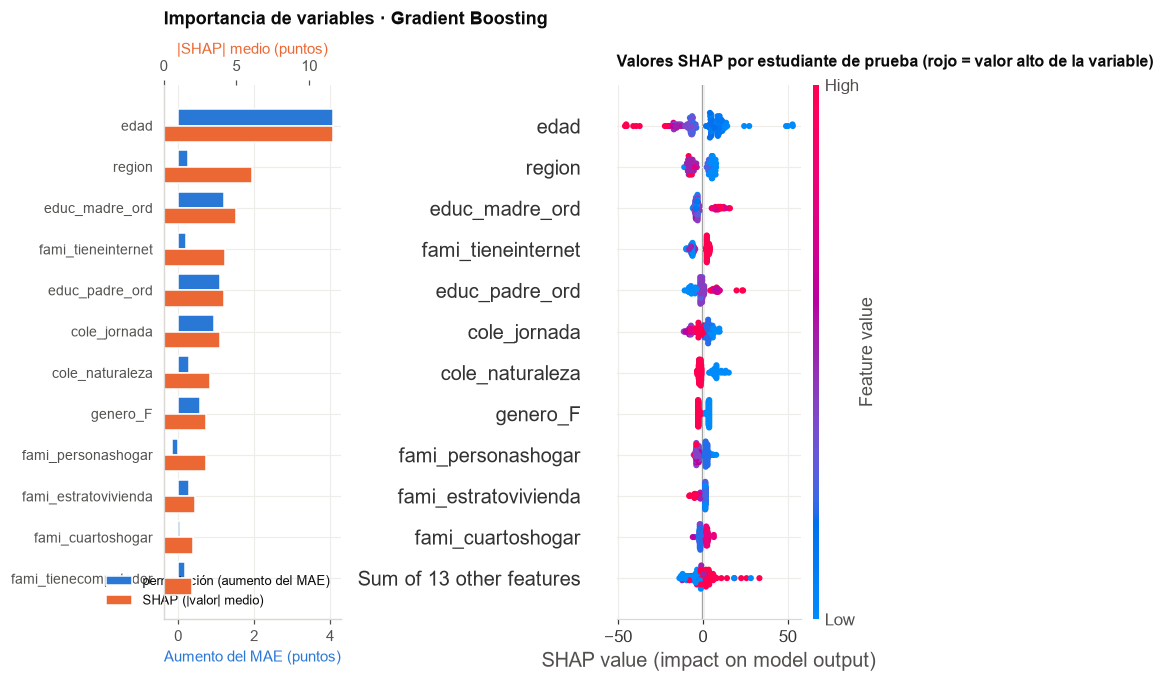

In [13]:
candidatos_arboles = {k: v for k, v in modelos_reg.items() if k in ("Random Forest", "Gradient Boosting")}
MODELO_INTERP = MEJOR_REG if MEJOR_REG in candidatos_arboles else resumen_reg.loc[list(candidatos_arboles)].index[0]
modelo_i = modelos_reg[MODELO_INTERP][0]
print(f"Modelo interpretado: {MODELO_INTERP}" + ("" if MODELO_INTERP == MEJOR_REG else f" (el mejor global es {MEJOR_REG}, que no es un modelo de árboles)"))

pi = permutation_importance(modelo_i, Xa["test"], y_test, scoring="neg_mean_absolute_error", n_repeats=10, random_state=RANDOM_STATE, n_jobs=N_JOBS)
imp_perm = pd.Series(pi.importances_mean, index=Xa["test"].columns).sort_values(ascending=False)

pred_test = modelo_i.predict(Xa["test"])
try:
    sv = shap.TreeExplainer(modelo_i)(Xa["test"], check_additivity=False); metodo = "TreeExplainer"
    err = float(np.abs(sv.values.sum(axis=1) + sv.base_values - pred_test).mean())
    if err > 1: raise RuntimeError(f"aditividad {err:.1f}")
except Exception as e:
    explicador = shap.Explainer(modelo_i.predict, shap.maskers.Independent(Xa["train"], max_samples=100), algorithm="permutation", seed=RANDOM_STATE)
    sv = explicador(Xa["test"], max_evals=2 * Xa["test"].shape[1] + 1, silent=True); metodo = f"explicador por permutación ({e})"
    err = float(np.abs(sv.values.sum(axis=1) + sv.base_values - pred_test).mean())
print(f"SHAP con {metodo} · error de aditividad medio {err:.3f} puntos")
imp_shap = pd.Series(np.abs(sv.values).mean(axis=0), index=Xa["test"].columns).sort_values(ascending=False)
importancias = pd.DataFrame({"permutación (aumento del MAE)": imp_perm, "SHAP (|valor| medio)": imp_shap}).sort_values("SHAP (|valor| medio)", ascending=False)
importancias.to_csv(PROCESSED_DIR / "importancias.csv"); display(importancias.head(12).round(2).T)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.3]})
top = importancias.head(12)
yy = np.arange(len(top)); axes[0].barh(yy - 0.2, top["permutación (aumento del MAE)"], height=0.4, color=C_BASE, label="permutación (aumento del MAE)")
ax2 = axes[0].twiny(); ax2.barh(yy + 0.2, top["SHAP (|valor| medio)"], height=0.4, color=C_ACCENT, label="SHAP (|valor| medio)"); ax2.grid(False)
axes[0].set_yticks(yy); axes[0].set_yticklabels(top.index, fontsize=9); axes[0].invert_yaxis(); axes[0].set_xlabel("Aumento del MAE (puntos)", color=C_BASE); ax2.set_xlabel("|SHAP| medio (puntos)", color=C_ACCENT)
axes[0].set_title(f"Importancia de variables · {MODELO_INTERP}"); h1, l1 = axes[0].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); axes[0].legend(h1 + h2, l1 + l2, frameon=False, loc="lower right", fontsize=8.5)
plt.sca(axes[1]); shap.plots.beeswarm(sv, max_display=12, show=False); axes[1].set_title("Valores SHAP por estudiante de prueba (rojo = valor alto de la variable)", fontsize=10.5)
fig.tight_layout(); save_fig(fig, "interpretability"); plt.show()

Se explica el **Gradient Boosting**, que fue el modelo ganador, y las cuentas de SHAP cuadran exactamente, con un error de aditividad de cero, así que sus valores son confiables. Los dos métodos coinciden en lo principal, la **edad** es por mucho la variable que más pesa, ya que en promedio mueve la predicción 11,6 puntos y al desordenarla el error empeora en 4,1 puntos, y le siguen la **educación de la madre** con 5,0 puntos, la **del padre** con 4,1, la **región** con 6,1, el **internet en la casa** con 4,2 y la **jornada** con 3,9.

Los dos métodos no coinciden del todo en la región y en el internet, porque SHAP les asigna un peso importante, pero al desordenarlas el error casi no empeora, apenas 0,27 y 0,21 puntos. La explicación es que esas variables se parecen a otras, como el tipo de colegio, el estrato o el computador, y cuando se desordena una de ellas el modelo se apoya en las demás, una limitación conocida de la permutación que justifica revisar los dos métodos.

El gráfico de puntos muestra la **dirección** de cada efecto, donde el color rojo corresponde a un valor alto de la variable, y en él se ve que ser mayor resta hasta 40 puntos y ser joven suma unos 10, que una mayor educación de los padres suma, que tener internet suma y que estudiar en jornada nocturna o sabatina resta. El género tiene un efecto pequeño pero constante a favor de los hombres, de 2,9 puntos en promedio, coherente con la brecha que mostró la exploración.

### 7.2 Cómo cambia la predicción con cada variable y con quién se equivoca el modelo

La **dependencia parcial** muestra cómo cambia, en promedio, el puntaje que predice el modelo cuando se mueve una sola variable y las demás se mantienen iguales, y es donde se ve si el modelo aprendió las curvas que mostró la exploración. El **análisis de errores**, por su parte, compara al mejor modelo con la regresión lineal por rangos de puntaje real y por grupos, como el tipo de colegio o la jornada, para identificar con quién sigue fallando.

Figura guardada: assets\images\data\partial_dependence.png


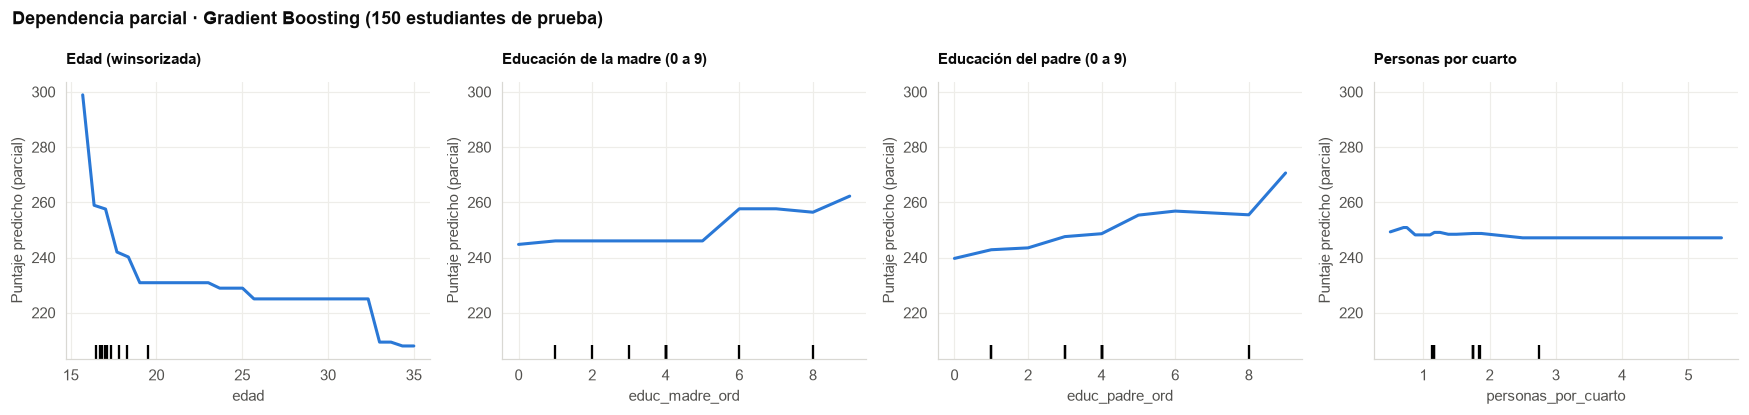

Por tramo de puntaje real:


tramo,"(0, 200]","(200, 250]","(250, 300]","(300, 500]"
n,26.000,56.000,42.000,26.000
sesgo Ridge,-45.900,-11.700,18.900,57.600
MAE Ridge,50.300,24.200,25.700,57.900
sesgo Gradient Boosting,-50.300,-13.700,14.600,56.800
MAE Gradient Boosting,51.000,24.000,23.900,56.800


Por naturaleza del colegio:


cole_naturaleza,NO OFICIAL,OFICIAL
n,34.000,116.000
sesgo Ridge,5.700,2.100
MAE Ridge,32.900,35.600
sesgo Gradient Boosting,3.500,-0.900
MAE Gradient Boosting,31.200,35.200


Por jornada:


cole_jornada,COMPLETA,MAÑANA,NOCHE,SABATINA,TARDE,UNICA
n,24.000,57.000,7.000,12.000,11.000,39.000
sesgo Ridge,4.400,1.900,8.300,5.100,-12.100,6.200
MAE Ridge,37.400,36.400,45.400,28.200,25.800,34.200
sesgo Gradient Boosting,-0.400,-1.100,8.600,-3.900,-18.100,7.100
MAE Gradient Boosting,36.800,38.500,39.200,20.000,21.700,33.900


,Ridge,Gradient Boosting
dentro de ±25 puntos (%),40.000,43.300
dentro de ±50 puntos (%),75.300,73.300


In [14]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
PartialDependenceDisplay.from_estimator(modelo_i, Xa["test"], NUM_COLS, method="brute", kind="average", percentiles=(0.02, 0.98), grid_resolution=30,
                                        ax=axes, line_kw={"color": C_BASE, "linewidth": 2}, random_state=RANDOM_STATE)
for ax, t in zip(axes, ["Edad (winsorizada)", "Educación de la madre (0 a 9)", "Educación del padre (0 a 9)", "Personas por cuarto"]):
    ax.set_title(t, fontsize=10); ax.set_ylabel("Puntaje predicho (parcial)")
fig.suptitle(f"Dependencia parcial · {MODELO_INTERP} (150 estudiantes de prueba)", x=0.01, ha="left", fontweight="bold"); fig.tight_layout(); save_fig(fig, "partial_dependence"); plt.show()

err = pd.DataFrame({"real": y_test, "ridge": y_test - ridge_ref.predict(Xl["test"]), "mejor": y_test - modelos_reg[MEJOR_REG][0].predict(modelos_reg[MEJOR_REG][1]["test"])})
err = err.join(df.loc[err.index, ["cole_naturaleza", "cole_jornada", "region"]]); err["tramo"] = pd.cut(err["real"], [0, 200, 250, 300, 500])
def resumen(grupo):
    g = err.groupby(grupo, observed=True)
    return pd.DataFrame({"n": g.size(), "sesgo Ridge": g["ridge"].mean(), "MAE Ridge": g["ridge"].apply(lambda s: s.abs().mean()),
                         f"sesgo {MEJOR_REG}": g["mejor"].mean(), f"MAE {MEJOR_REG}": g["mejor"].apply(lambda s: s.abs().mean())}).round(1)
print("Por tramo de puntaje real:"); display(resumen("tramo").T)
print("Por naturaleza del colegio:"); display(resumen("cole_naturaleza").T)
print("Por jornada:"); display(resumen("cole_jornada").T)
dentro = pd.DataFrame({m: [(err[c].abs() <= 25).mean() * 100, (err[c].abs() <= 50).mean() * 100] for m, c in [("Ridge", "ridge"), (MEJOR_REG, "mejor")]},
                      index=["dentro de ±25 puntos (%)", "dentro de ±50 puntos (%)"]).round(1); display(dentro)

Las curvas muestran que el *boosting* aprendió las formas que la exploración había anticipado. Con la **edad**, la predicción cae de golpe entre los 16 y los 19 años, de casi 300 a 231 puntos, luego se estabiliza y vuelve a bajar después de los 32, con la **educación de la madre** aparece un escalón claro de 11 puntos entre la educación técnica incompleta y la completa, con la **educación del padre** la predicción sube de forma casi continua, de 240 a 271 puntos entre *Ninguno* y *Postgrado*, y con las **personas por cuarto** la curva es casi plana, porque una vez el modelo conoce el estrato y el número de cuartos, el hacinamiento casi no le agrega información. Son escalones que una regresión lineal solo puede aproximar con una línea recta.

El análisis de errores explica por qué la mejora global es pequeña, pues el *boosting* acierta mejor en el centro de la distribución, donde se equivoca por unos 24 puntos entre los 200 y los 300 puntos de puntaje real, frente a 24 a 26 de Ridge, pero en los **extremos** falla igual que el modelo lineal, ya que a los estudiantes con menos de 200 puntos les predice en promedio **50 puntos de más** y a los que superan los 300, **57 puntos de menos**, porque el contexto no permite distinguir a un estudiante de 180 puntos de uno de 230, ni a uno de 320 de uno de 270.

Por grupos, el *boosting* mejora en los colegios privados, con 31,2 puntos de error frente a 32,9, y en las jornadas sabatina, con 20,0 frente a 28,2, y nocturna, con 39,2 frente a 45,4, donde aprovecha la relación entre la edad y la jornada, aunque empeora un poco en la jornada de la tarde, que solo tiene 11 estudiantes. En total, el modelo acierta dentro de un margen de **25 puntos en el 43 % de los casos**, frente al 40 % de Ridge, y dentro de 50 puntos en el 73 %.

## 8. Lo que se guarda

Se guardan los modelos finales de regresión y de clasificación, la red neuronal, los modelos de K-means con sus escaladores, el grupo al que pertenece cada estudiante, las métricas, las importancias y las predicciones sobre el grupo de prueba. El tablero del proyecto usa los mismos modelos con los mismos ajustes que se eligieron aquí y obtiene las mismas métricas.

In [15]:
joblib.dump(modelos_reg[MEJOR_REG][0] if not MEJOR_REG.startswith("Perceptrón") else mlp_reg.modelo.state_dict(), MODELS_DIR / "mejor_regresion.joblib")
joblib.dump({"nombre": MEJOR_REG, "representacion": "arboles" if modelos_reg[MEJOR_REG][1] is Xa else "lineal"}, MODELS_DIR / "mejor_regresion_info.joblib")
for nombre, (m, _) in {"Lasso": (lasso, None), "ElasticNet": (enet, None), "Random Forest": (rf_reg, None), "Gradient Boosting": (gb_reg, None)}.items():
    joblib.dump(m, MODELS_DIR / f"reg_{nombre.lower().replace(' ', '_')}.joblib")
torch.save(mlp.state_dict(), MODELS_DIR / "mlp_regresion.pt"); json.dump({"n_in": int(Xt_tr.shape[1]), "ocultas": [64, 32], "y_media": Y_MEDIA, "y_desv": Y_DESV, "mejor_epoca": mejor_epoca}, open(MODELS_DIR / "mlp_regresion.json", "w"))
joblib.dump(modelos_clf[MEJOR_CLF][0], MODELS_DIR / "mejor_clasificacion.joblib"); joblib.dump({"nombre": MEJOR_CLF, "representacion": "arboles" if modelos_clf[MEJOR_CLF][1] is Xa else "lineal"}, MODELS_DIR / "mejor_clasificacion_info.joblib")
joblib.dump(rf_clf, MODELS_DIR / "clf_random_forest.joblib"); joblib.dump(svm_clf, MODELS_DIR / "clf_svm.joblib"); joblib.dump(knn_clf, MODELS_DIR / "clf_knn.joblib")
joblib.dump({"kmeans_nivel": km_nivel, "kmeans_perfil": km_perfil, "scaler_nivel": RobustScaler().fit(Xc), "scaler_perfil": StandardScaler().fit(perfil.sub(perfil.mean(axis=1), axis=0))}, MODELS_DIR / "clustering.joblib")
pred = pd.DataFrame({"y_real": y_test, "nivel_real": c_test}, index=y_test.index)
for nombre, (m, rep) in modelos_reg.items(): pred["reg_" + nombre.split(" ")[0].lower()] = m.predict(rep["test"])
for nombre, (m, rep) in modelos_clf.items(): pred["clf_" + nombre.split(" ")[0].lower()] = m.predict(rep["test"])
pred.to_parquet(PROCESSED_DIR / "predicciones_fase3.parquet"); resumen_reg.to_csv(PROCESSED_DIR / "resumen_regresion.csv"); resumen_clf.to_csv(PROCESSED_DIR / "resumen_clasificacion.csv")
print("Modelos guardados:", sorted(p.name for p in MODELS_DIR.iterdir() if p.name != ".gitkeep"))

Modelos guardados: ['baseline_logistica.joblib', 'baseline_ridge.joblib', 'clf_knn.joblib', 'clf_random_forest.joblib', 'clf_svm.joblib', 'clustering.joblib', 'mejor_clasificacion.joblib', 'mejor_clasificacion_info.joblib', 'mejor_regresion.joblib', 'mejor_regresion_info.joblib', 'mlp_regresion.json', 'mlp_regresion.pt', 'prep_arboles.joblib', 'prep_lineal.joblib', 'reg_elasticnet.joblib', 'reg_gradient_boosting.joblib', 'reg_lasso.joblib', 'reg_random_forest.joblib']


Quedan guardados 18 archivos de modelos, entre ellos los dos preprocesadores y los dos modelos de referencia del cuaderno 02, los cuatro regresores nuevos y la red de PyTorch, los tres clasificadores, el ganador de cada bloque y los dos K-means con sus escaladores, mientras que las métricas, las importancias, el grupo de cada estudiante y las predicciones sobre el grupo de prueba quedan en `data/processed/`.

## 9. Conclusiones

Para predecir el puntaje se probaron seis modelos, tres lineales, Ridge, Lasso y ElasticNet, dos de árboles, Random Forest y Gradient Boosting, y una red neuronal en PyTorch, y todos rinden casi igual, pues se equivocan en promedio entre **33,8 y 35,2 puntos** y explican cerca del **30 %** de las diferencias entre estudiantes, con intervalos de confianza que se cruzan. El **Gradient Boosting** es el mejor según la validación cruzada y queda como modelo final, con un error de 34,3 puntos en prueba, un 18,7 % menos que predecir el promedio, y aunque la mejora frente a la regresión lineal es real, es pequeña, porque el límite lo ponen los datos, ya que el contexto del hogar y del colegio explica solo una parte del puntaje.

La red neuronal, con 6.657 pesos y apenas 700 estudiantes, alcanza a los demás modelos, con 34,4 puntos de error, solo gracias a la parada temprana en la época 13, y la curva de pérdida muestra cómo empieza a memorizar a partir de ese punto, lo que confirma que con tan pocos datos una red no supera a un modelo más sencillo.

Para predecir el nivel de desempeño, el Random Forest, la SVM y el KNN empatan con la regresión logística, con F1 macro entre 0,48 y 0,51. La **SVM** gana por validación cruzada y logra en prueba un F1 de 0,498, una exactitud de 0,500 y un AUC de 0,680, pero todos los modelos fallan en lo mismo, el nivel medio, porque los tercios separan a estudiantes casi iguales, y para un sistema de alertas tempranas conviene más preguntar solo por el riesgo de quedar en el nivel bajo, con un AUC de 0,72.

En cuanto a los grupos de estudiantes, el agrupamiento por nivel con K-means encuentra tres grupos claros, el de **alto desempeño**, con 423 estudiantes, 298 puntos de media y 83 % con internet, el de **desempeño bajo a medio**, con 557 estudiantes, 214 puntos y 86 % en colegios oficiales, y el de **adultos de jornada nocturna y sabatina**, con 20 estudiantes, 39 años y 190 puntos de media. Por fortalezas, K-means y el método jerárquico coinciden en una sola división, entre quienes sobresalen en lectura y flojean en inglés y quienes sobresalen en inglés, lo que sirve para orientar los refuerzos en inglés hacia los colegios oficiales, y DBSCAN confirma que los adultos de mayor edad son casos aislados y no un grupo propio.

Finalmente, SHAP y la permutación coinciden en que la **edad** es la variable que más pesa, seguida de la educación de los padres, la región, el internet en la casa y la jornada, y el modelo aprendió tanto la caída del puntaje entre los 16 y los 19 años como los escalones de la educación de los padres. Su límite está en los extremos, pues a los estudiantes con más de 300 puntos les predice unos 57 de menos y a los que tienen menos de 200, unos 50 de más, y por eso sirve para entender las desigualdades, pero no para tomar decisiones sobre un estudiante en particular.